# SISTIA - Asistente Inteligente de Soporte Técnico

## Avance de Proyecto 1
### Desarrollo de aplicaciones con inteligencia artificial

**Descripción del proyecto**

SISTIA es un prototipo de chatbot desarrollado en Python y NLTK,
orientado a proporcionar asistencia técnica básica a los colaboradores
de un hotel.

El sistema utiliza procesamiento de texto y reglas de decisión para
identificar problemas frecuentes y guiar al usuario mediante preguntas
y recomendaciones.

**Categorías de atención:**

1. Problemas de impresoras.
2. Problemas de conectividad a internet.
3. Problemas de computadoras.
4. Problemas de acceso a sistemas.
5. Problemas de correo electrónico.

**Objetivo**

Desarrollar un chatbot basado en reglas que permita orientar a los
colaboradores en la identificación y solución de incidencias técnicas
comunes, evitando verificaciones repetidas y recomendando la
intervención del departamento de Sistemas cuando sea necesario.

**Tecnologías utilizadas**

- Python 3.
- NLTK.
- Google Colab.
- Diccionarios de Python.
- Funciones y estructuras condicionales.

## 2. Configuración del entorno de trabajo

En esta sección se importan las librerías necesarias para el
funcionamiento de SISTIA y se verifica que el entorno de
Google Colab esté preparado correctamente.

In [26]:
# ==================================================
# SISTIA - ASISTENTE INTELIGENTE DE SOPORTE TÉCNICO
# SECCIÓN 2: CONFIGURACIÓN DEL ENTORNO
# ==================================================

# Importar librerías
import sys
import nltk

# Mostrar información del entorno
print("=" * 45)
print("SISTIA - ASISTENTE INTELIGENTE")
print("=" * 45)

print("Versión de Python:", sys.version.split()[0])
print("Versión de NLTK:", nltk.__version__)

print("\nEntorno de trabajo preparado correctamente.")

SISTIA - ASISTENTE INTELIGENTE
Versión de Python: 3.13.18
Versión de NLTK: 3.9.1

Entorno de trabajo preparado correctamente.


## 3. Base de conocimiento de SISTIA

La base de conocimiento contiene las categorías de soporte técnico
y diferentes expresiones utilizadas por los colaboradores para
reportar incidencias.

Se utiliza un diccionario de Python para organizar las expresiones
asociadas con cada categoría.

Esta estructura permite que SISTIA identifique el tipo de problema
y seleccione posteriormente el diagnóstico correspondiente.

In [27]:
# ==================================================
# SISTIA - BASE DE CONOCIMIENTO
# SECCIÓN 3: CATEGORÍAS DE SOPORTE TÉCNICO
# ==================================================

categorias = {

    "impresoras": [
        "mi impresora no funciona",
        "no puedo imprimir",
        "la impresora tiene un problema",
        "la impresora no imprime",
        "la impresora está desconectada",
        "la impresora no tiene papel",
        "hay papel atorado en la impresora"
    ],

    "internet": [
        "no tengo internet",
        "no puedo conectarme a internet",
        "mi computadora no tiene internet",
        "la conexión de red no funciona",
        "el internet está muy lento",
        "no puedo abrir páginas de internet",
        "se desconecta el internet"
    ],

    "computadoras": [
        "mi computadora no enciende",
        "la computadora no funciona",
        "mi computadora tiene un problema",
        "la computadora enciende pero no muestra imagen",
        "mi computadora no da video",
        "windows no inicia",
        "mi computadora se queda congelada"
    ],

    "sistemas": [
        "no puedo entrar a navision",
        "no puedo acceder a zennio",
        "no puedo entrar a salto systems",
        "no puedo entrar a total pos",
        "el sistema no funciona",
        "la página del sistema no abre",
        "mi contraseña del sistema no funciona"
    ],

    "correo": [
        "no puedo enviar correos",
        "no recibo correos",
        "outlook no abre",
        "mi correo no funciona",
        "outlook no me deja enviar correos",
        "no puedo recibir correos",
        "outlook solicita actualizar contraseña"
    ]

}

# Mostrar las categorías registradas

print("=" * 45)
print("BASE DE CONOCIMIENTO DE SISTIA")
print("=" * 45)

for categoria, expresiones in categorias.items():

    print(
        f"{categoria.upper()}: "
        f"{len(expresiones)} expresiones registradas"
    )

print("=" * 45)
print("Total de categorías:", len(categorias))
print(
    "Total de expresiones:",
    sum(len(expresiones) for expresiones in categorias.values())
)

BASE DE CONOCIMIENTO DE SISTIA
IMPRESORAS: 7 expresiones registradas
INTERNET: 7 expresiones registradas
COMPUTADORAS: 7 expresiones registradas
SISTEMAS: 7 expresiones registradas
CORREO: 7 expresiones registradas
Total de categorías: 5
Total de expresiones: 35


## 4. Procesamiento de texto y reconocimiento de categorías

SISTIA utiliza técnicas básicas de procesamiento de lenguaje natural
mediante NLTK para analizar los mensajes de los colaboradores.

El sistema normaliza el texto, separa las palabras y compara su
contenido con las expresiones almacenadas en la base de conocimiento.

A partir de las coincidencias encontradas, determina la categoría
de soporte técnico correspondiente.

Este procedimiento utiliza reglas y coincidencias de palabras,
sin necesidad de entrenar un modelo de aprendizaje automático.

In [28]:
# ==================================================
# SISTIA - PROCESAMIENTO DE LENGUAJE NATURAL
# SECCIÓN 4: RECONOCIMIENTO DE CATEGORÍAS
# ==================================================

import re
import unicodedata
from nltk.tokenize import wordpunct_tokenize


# Palabras comunes que no aportan mucho al diagnóstico
palabras_comunes = {
    "mi", "mis", "la", "el", "los", "las",
    "un", "una", "de", "del", "en", "a",
    "con", "por", "porque", "que", "tengo",
    "puedo", "me", "no", "esta", "este",
    "y", "pero"
}


# Normalizar texto
def normalizar_texto(texto):

    texto = texto.lower()

    # Eliminar acentos
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )

    return texto


# Obtener palabras importantes
def obtener_palabras(texto):

    texto = normalizar_texto(texto)

    palabras = wordpunct_tokenize(texto)

    palabras = {
        palabra
        for palabra in palabras
        if palabra.isalpha()
        and palabra not in palabras_comunes
    }

    return palabras


# Identificar categoría del mensaje
def identificar_categoria(mensaje):

    palabras_mensaje = obtener_palabras(mensaje)

    puntuaciones = {}

    for categoria, expresiones in categorias.items():

        mejor_puntuacion = 0

        for expresion in expresiones:

            palabras_expresion = obtener_palabras(expresion)

            coincidencias = palabras_mensaje.intersection(
                palabras_expresion
            )

            puntuacion = len(coincidencias)

            if puntuacion > mejor_puntuacion:
                mejor_puntuacion = puntuacion

        puntuaciones[categoria] = mejor_puntuacion

    mejor_categoria = max(
        puntuaciones,
        key=puntuaciones.get
    )

    if puntuaciones[mejor_categoria] == 0:
        return "desconocido"

    return mejor_categoria


print("SISTIA: Procesamiento de texto configurado correctamente.")

SISTIA: Procesamiento de texto configurado correctamente.


### 4.1. Pruebas de reconocimiento de categorías

Se realizan diez pruebas para evaluar la capacidad de SISTIA
de identificar diferentes problemas técnicos a partir de
mensajes escritos por los colaboradores.

Cada mensaje se compara con la base de conocimiento y se
verifica si la categoría identificada corresponde con la
categoría esperada.

Estas pruebas permiten detectar posibles errores en el
reconocimiento antes de integrar los diagnósticos interactivos.

In [29]:
# ==================================================
# SISTIA - PRUEBAS DE RECONOCIMIENTO
# SECCIÓN 4.1
# ==================================================

mensajes_prueba = [
    ("Mi impresora no funciona", "impresoras"),
    ("No puedo imprimir", "impresoras"),
    ("No tengo internet en mi computadora", "internet"),
    ("No puedo conectarme a internet", "internet"),
    ("Mi computadora no enciende", "computadoras"),
    ("La computadora enciende pero no muestra imagen", "computadoras"),
    ("No puedo entrar a Navision", "sistemas"),
    ("No puedo acceder a Zennio", "sistemas"),
    ("Outlook no me deja enviar correos", "correo"),
    ("No puedo recibir correos", "correo")
]

aciertos = 0

print("=" * 55)
print("PRUEBAS DE RECONOCIMIENTO - SISTIA")
print("=" * 55)

for numero, (mensaje, esperado) in enumerate(mensajes_prueba, start=1):

    resultado = identificar_categoria(mensaje)

    if resultado == esperado:
        estado = "CORRECTO"
        aciertos += 1
    else:
        estado = "INCORRECTO"

    print(f"\nPrueba {numero}")
    print("Mensaje:", mensaje)
    print("Categoría esperada:", esperado)
    print("Categoría identificada:", resultado)
    print("Resultado:", estado)

total = len(mensajes_prueba)
porcentaje = (aciertos / total) * 100

print("\n" + "=" * 55)
print("RESUMEN DE RESULTADOS")
print("=" * 55)
print("Total de pruebas:", total)
print("Aciertos:", aciertos)
print("Errores:", total - aciertos)
print(f"Porcentaje de aciertos: {porcentaje:.2f}%")

PRUEBAS DE RECONOCIMIENTO - SISTIA

Prueba 1
Mensaje: Mi impresora no funciona
Categoría esperada: impresoras
Categoría identificada: impresoras
Resultado: CORRECTO

Prueba 2
Mensaje: No puedo imprimir
Categoría esperada: impresoras
Categoría identificada: impresoras
Resultado: CORRECTO

Prueba 3
Mensaje: No tengo internet en mi computadora
Categoría esperada: internet
Categoría identificada: internet
Resultado: CORRECTO

Prueba 4
Mensaje: No puedo conectarme a internet
Categoría esperada: internet
Categoría identificada: internet
Resultado: CORRECTO

Prueba 5
Mensaje: Mi computadora no enciende
Categoría esperada: computadoras
Categoría identificada: computadoras
Resultado: CORRECTO

Prueba 6
Mensaje: La computadora enciende pero no muestra imagen
Categoría esperada: computadoras
Categoría identificada: computadoras
Resultado: CORRECTO

Prueba 7
Mensaje: No puedo entrar a Navision
Categoría esperada: sistemas
Categoría identificada: sistemas
Resultado: CORRECTO

Prueba 8
Mensaje: No p

## 5. Diagnóstico de impresoras

Esta sección contiene el flujo de diagnóstico para problemas
relacionados con impresoras.

SISTIA pregunta al colaborador qué verificaciones ha realizado
previamente y utiliza sus respuestas para evitar repetir pasos.

El diagnóstico contempla la alimentación eléctrica, disponibilidad
de papel y presencia de mensajes de error.

Cuando las verificaciones no permiten resolver el problema,
el chatbot recomienda contactar al departamento de Sistemas.

In [30]:
# ==================================================
# SISTIA - DIAGNÓSTICO DE IMPRESORAS
# SECCIÓN 5
# ==================================================

def preguntar_opcion(pregunta, opciones):

    while True:

        print("\nSISTIA:", pregunta)

        for numero, descripcion in opciones.items():
            print(f"{numero}. {descripcion}")

        respuesta = input("Colaborador: ").strip()

        if respuesta in opciones:
            return respuesta

        print("SISTIA: Selecciona una opción válida.")


def diagnostico_impresora():

    print("\n" + "=" * 40)
    print("DIAGNÓSTICO DE IMPRESORA - SISTIA")
    print("=" * 40)

    estado = {
        "encendida": None,
        "papel": None,
        "error": None,
        "solucionado": False
    }

    opcion = preguntar_opcion(
        "¿Qué has verificado hasta ahora?",
        {
            "1": "La impresora está encendida.",
            "2": "La impresora tiene papel.",
            "3": "Revisé si muestra mensajes de error.",
            "4": "Ya revisé todo lo anterior.",
            "5": "No he revisado nada."
        }
    )

    # Registrar verificaciones previas
    if opcion == "1":
        estado["encendida"] = True

    elif opcion == "2":
        estado["papel"] = True

    elif opcion == "3":
        estado["error"] = "revisado"

    elif opcion == "4":
        estado["encendida"] = True
        estado["papel"] = True
        estado["error"] = "revisado"

    # Verificar alimentación
    if estado["encendida"] is None:

        respuesta = preguntar_opcion(
            "¿La impresora está encendida?",
            {
                "1": "Sí",
                "2": "No",
                "3": "No lo he verificado"
            }
        )

        if respuesta == "1":
            estado["encendida"] = True

        elif respuesta == "2":
            print("\nSISTIA: Verifica que esté conectada.")
            print("SISTIA: Enciende la impresora.")

            estado["encendida"] = False

        else:
            print("\nSISTIA: Revisa el indicador de encendido.")

    # Verificar papel
    if estado["papel"] is None:

        respuesta = preguntar_opcion(
            "¿La impresora tiene papel?",
            {
                "1": "Sí",
                "2": "No",
                "3": "No lo he verificado"
            }
        )

        if respuesta == "1":
            estado["papel"] = True

        elif respuesta == "2":
            print("\nSISTIA: Coloca papel en la bandeja.")
            estado["papel"] = False

        else:
            print("\nSISTIA: Revisa la bandeja de papel.")

    # Verificar mensajes de error
    if estado["error"] is None:

        respuesta = preguntar_opcion(
            "¿La impresora muestra algún mensaje de error?",
            {
                "1": "Sí",
                "2": "No",
                "3": "No lo he verificado"
            }
        )

        if respuesta == "1":
            estado["error"] = True

            print("\nSISTIA: Revisa el mensaje mostrado.")
            print("SISTIA: No fuerces componentes internos.")

        elif respuesta == "2":
            estado["error"] = False

        else:
            print("\nSISTIA: Revisa la pantalla de la impresora.")

    # Confirmar resultado
    respuesta = preguntar_opcion(
        "¿La impresora ya funciona correctamente?",
        {
            "1": "Sí",
            "2": "No"
        }
    )

    estado["solucionado"] = respuesta == "1"

    # Mostrar resumen
    print("\n" + "=" * 40)
    print("RESUMEN DEL DIAGNÓSTICO")
    print("=" * 40)

    for clave, valor in estado.items():
        print(f"{clave}: {valor}")

    if estado["solucionado"]:

        print("\nSISTIA: Excelente.")
        print("SISTIA: El problema quedó solucionado.")

    else:

        print("\nSISTIA: El problema continúa.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    return estado

## 6. Diagnóstico de conectividad a internet

Esta sección permite identificar problemas relacionados con
la conectividad de red de las computadoras del hotel.

SISTIA verifica la conexión física del cable Ethernet,
el acceso a páginas de internet y la disponibilidad de
los sistemas internos.

El diagnóstico utiliza reglas condicionales para distinguir
entre problemas de acceso a internet, problemas de sistemas
internos y fallas generales de conectividad.

Cuando el problema requiere intervención técnica,
el chatbot recomienda contactar al departamento de Sistemas.

In [31]:
# ==================================================
# SISTIA - DIAGNÓSTICO DE INTERNET
# SECCIÓN 6
# ==================================================

def diagnostico_internet():

    print("\n" + "=" * 40)
    print("DIAGNÓSTICO DE INTERNET - SISTIA")
    print("=" * 40)

    estado = {
        "cable_revisado": False,
        "internet": None,
        "sistemas_internos": None,
        "solucionado": False
    }

    # Verificación del cable de red
    respuesta = preguntar_opcion(
        "¿Ya verificaste que el cable de red esté conectado?",
        {
            "1": "Sí, está conectado.",
            "2": "No, está desconectado.",
            "3": "No lo he revisado."
        }
    )

    if respuesta == "1":

        estado["cable_revisado"] = True
        print("\nSISTIA: Perfecto, el cable está conectado.")

    elif respuesta == "2":

        print("\nSISTIA: Conecta correctamente el cable Ethernet.")
        print("SISTIA: Verifica que quede bien conectado.")

        estado["cable_revisado"] = True

    else:

        print("\nSISTIA: Revisa el cable de red de tu computadora.")
        print("SISTIA: Comprueba que esté conectado correctamente.")

    # Verificación de internet
    respuesta = preguntar_opcion(
        "¿Puedes abrir una página de internet, como Google?",
        {
            "1": "Sí",
            "2": "No"
        }
    )

    estado["internet"] = respuesta == "1"

    # Verificación de sistemas internos
    respuesta = preguntar_opcion(
        "¿Puedes acceder a los sistemas internos del hotel?",
        {
            "1": "Sí",
            "2": "No"
        }
    )

    estado["sistemas_internos"] = respuesta == "1"

    # Interpretar resultados
    print("\n" + "=" * 40)
    print("RESULTADO DEL DIAGNÓSTICO")
    print("=" * 40)

    if estado["internet"] and estado["sistemas_internos"]:

        print("\nSISTIA: La conectividad parece funcionar correctamente.")

    elif estado["internet"] and not estado["sistemas_internos"]:

        print("\nSISTIA: Internet funciona, pero los sistemas internos no.")
        print("SISTIA: Contacta a Sistemas e indica qué sistema no abre.")

    elif not estado["internet"] and estado["sistemas_internos"]:

        print("\nSISTIA: Los sistemas internos funcionan, pero internet no.")
        print("SISTIA: Contacta a Sistemas para revisar el acceso a internet.")

    else:

        print("\nSISTIA: No hay acceso a internet ni a los sistemas internos.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    # Confirmación del colaborador
    respuesta = preguntar_opcion(
        "¿El problema quedó solucionado?",
        {
            "1": "Sí",
            "2": "No"
        }
    )

    estado["solucionado"] = respuesta == "1"

    if estado["solucionado"]:

        print("\nSISTIA: Excelente, el problema quedó solucionado.")

    else:

        print("\nSISTIA: El problema continúa.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    # Resumen
    print("\n" + "=" * 40)
    print("RESUMEN DEL DIAGNÓSTICO")
    print("=" * 40)

    for clave, valor in estado.items():
        print(f"{clave}: {valor}")

    return estado

## 7. Diagnóstico de computadoras

Esta sección permite orientar a los colaboradores cuando
una computadora no enciende, no muestra imagen o presenta
problemas durante el inicio de Windows.

SISTIA utiliza preguntas estructuradas para identificar
el tipo de falla y recomendar verificaciones básicas.

El diagnóstico contempla la alimentación eléctrica,
el indicador de encendido, el funcionamiento del monitor
y los mensajes de error de Windows.

Las acciones que requieren manipulación de componentes
internos o procedimientos avanzados se canalizan al
departamento de Sistemas.

In [32]:
# ==================================================
# SISTIA - DIAGNÓSTICO DE COMPUTADORAS
# SECCIÓN 7
# ==================================================

def diagnostico_computadora():

    print("\n" + "=" * 45)
    print("DIAGNÓSTICO DE COMPUTADORA - SISTIA")
    print("=" * 45)

    estado = {
        "problema": None,
        "energia": None,
        "indicador": None,
        "monitor": None,
        "solucionado": False
    }

    # Identificar el problema principal
    opcion = preguntar_opcion(
        "¿Qué sucede con tu computadora?",
        {
            "1": "No enciende.",
            "2": "Enciende, pero no muestra imagen.",
            "3": "Windows no inicia correctamente."
        }
    )

    # ==============================================
    # PC-01: LA COMPUTADORA NO ENCIENDE
    # ==============================================

    if opcion == "1":

        estado["problema"] = "No enciende"

        respuesta = preguntar_opcion(
            "¿Ya verificaste el cable de alimentación?",
            {
                "1": "Sí, está conectado.",
                "2": "No, está desconectado.",
                "3": "No lo he revisado."
            }
        )

        if respuesta == "1":

            estado["energia"] = True

            print("\nSISTIA: El cable de alimentación está conectado.")
            print("SISTIA: Revisa si el equipo muestra luces o ventiladores.")

        elif respuesta == "2":

            estado["energia"] = False

            print("\nSISTIA: Conecta correctamente el cable de alimentación.")
            print("SISTIA: Intenta encender la computadora normalmente.")

        else:

            print("\nSISTIA: Verifica que el cable de alimentación")
            print("esté conectado a la computadora y a la corriente.")

    # ==============================================
    # PC-02: ENCIENDE, PERO NO MUESTRA IMAGEN
    # ==============================================

    elif opcion == "2":

        estado["problema"] = "No muestra imagen"

        respuesta = preguntar_opcion(
            "¿De qué color está el indicador de encendido?",
            {
                "1": "Blanco.",
                "2": "Naranja.",
                "3": "Está apagado."
            }
        )

        if respuesta == "1":

            estado["indicador"] = "Blanco"

            print("\nSISTIA: El equipo presenta señales de encendido.")

            respuesta = preguntar_opcion(
                "¿El monitor está encendido?",
                {
                    "1": "Sí",
                    "2": "No",
                    "3": "No lo he revisado"
                }
            )

            if respuesta == "1":

                estado["monitor"] = True

                print("\nSISTIA: Verifica que el cable de video")
                print("esté conectado correctamente.")
                print("SISTIA: Revisa si el monitor muestra 'Sin señal'.")

            elif respuesta == "2":

                estado["monitor"] = False

                print("\nSISTIA: Enciende el monitor.")
                print("SISTIA: Verifica su cable de alimentación.")

            else:

                print("\nSISTIA: Revisa que el monitor")
                print("esté conectado y encendido.")

        elif respuesta == "2":

            estado["indicador"] = "Naranja"

            print("\nSISTIA: El indicador naranja puede señalar")
            print("una condición que requiere revisión técnica.")
            print("SISTIA: Contacta al departamento de Sistemas.")
            print("SISTIA: No abras el gabinete de la computadora.")

        else:

            estado["indicador"] = "Apagado"

            print("\nSISTIA: No se observan señales de encendido.")
            print("SISTIA: Verifica el cable de alimentación.")
            print("SISTIA: Si continúa igual, contacta a Sistemas.")

    # ==============================================
    # PC-03: WINDOWS NO INICIA
    # ==============================================

    elif opcion == "3":

        estado["problema"] = "Windows no inicia"

        respuesta = preguntar_opcion(
            "¿Qué sucede cuando intentas iniciar Windows?",
            {
                "1": "Aparece un mensaje de error.",
                "2": "Se queda congelado en el logotipo.",
                "3": "Se reinicia repetidamente.",
                "4": "La pantalla permanece negra."
            }
        )

        errores = {
            "1": "Mensaje de error",
            "2": "Congelado en el logotipo",
            "3": "Reinicio repetitivo",
            "4": "Pantalla negra"
        }

        estado["indicador"] = errores[respuesta]

        print("\nSISTIA: El inicio de Windows requiere revisión.")
        print("SISTIA: Contacta al departamento de Sistemas.")
        print("SISTIA: No fuerces el apagado del equipo")
        print("sin autorización del personal de Sistemas.")

    # ==============================================
    # CONFIRMAR RESULTADO
    # ==============================================

    respuesta = preguntar_opcion(
        "¿El problema quedó solucionado?",
        {
            "1": "Sí",
            "2": "No"
        }
    )

    estado["solucionado"] = respuesta == "1"

    if estado["solucionado"]:

        print("\nSISTIA: Excelente, el problema quedó solucionado.")

    else:

        print("\nSISTIA: El problema continúa.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    # ==============================================
    # RESUMEN DEL DIAGNÓSTICO
    # ==============================================

    print("\n" + "=" * 45)
    print("RESUMEN DEL DIAGNÓSTICO")
    print("=" * 45)

    for clave, valor in estado.items():
        print(f"{clave}: {valor}")

    return estado

## 8. Diagnóstico de sistemas del hotel

Esta sección permite identificar problemas de acceso a los sistemas
Navision, SALTO Systems, Total POS y Zennio.

SISTIA orienta al colaborador mediante preguntas y recomendaciones,
sin solicitar contraseñas ni modificar configuraciones de seguridad.

In [33]:
# ==========================================
# SECCIÓN 8: DIAGNÓSTICO DE SISTEMAS
# SISTIA - ASISTENTE INTELIGENTE
# ==========================================

def diagnostico_sistemas():

    print("\n" + "=" * 40)
    print(" DIAGNÓSTICO DE SISTEMAS - SISTIA")
    print("=" * 40)

    sistemas = {
        "1": "Navision",
        "2": "SALTO Systems",
        "3": "Total POS",
        "4": "Zennio"
    }

    print("\nSISTIA: ¿Con qué sistema tienes problemas?")

    for numero, nombre in sistemas.items():
        print(f"{numero}. {nombre}")

    opcion = input("Colaborador: ").strip()

    if opcion not in sistemas:
        print("\nSISTIA: No reconozco el sistema seleccionado.")
        return

    sistema = sistemas[opcion]

    print(f"\nSISTIA: Entiendo que tienes problemas con {sistema}.")

    print("\nSISTIA: ¿Qué problema estás presentando?")
    print("1. No puedo iniciar sesión.")
    print("2. La página del sistema no abre.")
    print("3. Aparece un mensaje de error.")

    problema = input("Colaborador: ").strip()

    if problema == "1":

        print("\nSISTIA: ¿El problema está relacionado con tu contraseña?")
        print("1. Sí")
        print("2. No")

        respuesta = input("Colaborador: ").strip()

        if respuesta == "1":

            if sistema == "Navision":

                print("\nSISTIA: Navision utiliza las credenciales de Windows.")
                print("SISTIA: ¿Windows te solicita actualizar tu contraseña?")
                print("1. Sí")
                print("2. No")

                actualizar = input("Colaborador: ").strip()

                if actualizar == "1":

                    print("\nSISTIA: Guarda tus documentos abiertos.")
                    print("SISTIA: Reinicia Windows normalmente.")
                    print("SISTIA: Sigue las indicaciones para actualizar tu contraseña.")

                elif actualizar == "2":

                    print("\nSISTIA: Contacta al departamento de Sistemas.")
                    print("SISTIA: No compartas tu contraseña.")

                else:
                    print("\nSISTIA: No reconozco la respuesta.")

            else:

                print(f"\nSISTIA: El acceso a {sistema} requiere revisión.")
                print("SISTIA: Contacta al departamento de Sistemas.")
                print("SISTIA: Nunca compartas tu contraseña.")

        elif respuesta == "2":

            print("\nSISTIA: Contacta al departamento de Sistemas.")
            print("SISTIA: Indica qué sucede al intentar iniciar sesión.")

        else:
            print("\nSISTIA: No reconozco la respuesta.")

    elif problema == "2":

        diagnostico_pagina_sistema(sistema)

    elif problema == "3":

        diagnostico_error_sistema(sistema)

    else:

        print("\nSISTIA: No reconozco el problema seleccionado.")

    print("\n" + "=" * 40)
    print(" FIN DEL DIAGNÓSTICO")
    print("=" * 40)

In [34]:
# ==========================================
# SISTIA - MEJORA DE DIAGNÓSTICO DE SISTEMAS
# Ruta SIS-02: La página del sistema no abre
# ==========================================

def diagnostico_pagina_sistema(sistema):

    print("\n" + "=" * 40)
    print(" DIAGNÓSTICO DE ACCESO WEB - SISTIA")
    print("=" * 40)

    estado = {
        "sistema": sistema,
        "internet": None,
        "otros_usuarios": None,
        "solucionado": None
    }

    print(f"\nSISTIA: Vamos a revisar el acceso a {sistema}.")

    print("\nSISTIA: ¿Qué has verificado hasta ahora?")
    print("1. Ya comprobé que tengo internet.")
    print("2. Ya revisé si otros compañeros pueden abrir el sistema.")
    print("3. Ya realicé ambas verificaciones.")
    print("4. No he revisado nada.")

    opcion = input("Colaborador: ").strip()

    if opcion not in ("1", "2", "3", "4"):
        print("\nSISTIA: No reconozco la opción seleccionada.")
        return estado

    # El colaborador ya realizó ambas verificaciones
    if opcion == "3":

        print("\nSISTIA: Ya realizaste ambas verificaciones.")
        print("SISTIA: ¿Cuáles fueron los resultados?")

        print("1. Tengo internet y otros compañeros pueden abrir el sistema.")
        print("2. Tengo internet, pero otros compañeros tampoco pueden abrirlo.")
        print("3. No tengo internet, pero otros compañeros sí pueden abrirlo.")
        print("4. No tengo internet y otros compañeros tampoco pueden abrirlo.")

        resultado = input("Colaborador: ").strip()

        resultados = {
            "1": (True, True),
            "2": (True, False),
            "3": (False, True),
            "4": (False, False)
        }

        if resultado not in resultados:
            print("SISTIA: No reconozco la opción seleccionada.")
            return estado

        estado["internet"], estado["otros_usuarios"] = resultados[resultado]

        if resultado == "1":
            print("\nSISTIA: Tu conexión funciona.")
            print("SISTIA: El problema parece afectar únicamente a tu acceso.")
            print("SISTIA: Contacta al departamento de Sistemas.")

        elif resultado == "2":
            print("\nSISTIA: Otros compañeros tampoco pueden abrir el sistema.")
            print("SISTIA: Podría tratarse de una incidencia general.")
            print("SISTIA: Contacta al departamento de Sistemas.")

        elif resultado == "3":
            print("\nSISTIA: Tu computadora presenta problemas de conectividad.")
            print("SISTIA: Contacta al departamento de Sistemas.")

        elif resultado == "4":
            print("\nSISTIA: Hay problemas de conectividad y acceso al sistema.")
            print("SISTIA: Contacta al departamento de Sistemas.")

        estado["solucionado"] = False

        return estado

    # Verificación de internet
    if opcion in ("1", "3"):

        print("\nSISTIA: ¿Confirmaste que puedes abrir otras páginas web?")
        print("1. Sí")
        print("2. No")

        respuesta = input("Colaborador: ").strip()

        if respuesta == "1":
            estado["internet"] = True
        elif respuesta == "2":
            estado["internet"] = False
        else:
            print("SISTIA: Respuesta no válida.")
            return estado

    else:

        print("\nSISTIA: Primero verifica si puedes abrir una página como Google.")
        print("1. Sí, puedo abrirla.")
        print("2. No puedo abrirla.")

        respuesta = input("Colaborador: ").strip()

        if respuesta == "1":
            estado["internet"] = True
        elif respuesta == "2":
            estado["internet"] = False
        else:
            print("SISTIA: Respuesta no válida.")
            return estado


    # Verificación de otros colaboradores
    if estado["internet"] is True:

        if opcion in ("2", "3"):
            print("\nSISTIA: Según tu revisión,")
            print("¿otros compañeros pueden abrir el sistema?")
        else:
            print("\nSISTIA: Comprueba si otro compañero")
            print("puede abrir el mismo sistema.")

        print("1. Sí")
        print("2. No")
        print("3. No lo sé")

        respuesta = input("Colaborador: ").strip()

        if respuesta == "1":
            estado["otros_usuarios"] = True
        elif respuesta == "2":
            estado["otros_usuarios"] = False
        elif respuesta == "3":
            estado["otros_usuarios"] = None
        else:
            print("SISTIA: Respuesta no válida.")
            return estado

    # Evaluación del diagnóstico
    print("\n" + "=" * 40)
    print(" RESULTADO DEL DIAGNÓSTICO")
    print("=" * 40)

    if estado["internet"] is False:

        print("\nSISTIA: Se detectó un problema de conectividad.")
        print("SISTIA: Es necesario revisar la conexión de red.")
        print("SISTIA: Contacta a Sistemas si el problema continúa.")

    elif estado["otros_usuarios"] is True:

        print("\nSISTIA: Otros colaboradores pueden abrir el sistema.")
        print("SISTIA: El problema podría estar relacionado")
        print("con tu computadora, navegador o acceso.")
        print("SISTIA: Contacta a Sistemas para continuar la revisión.")

    elif estado["otros_usuarios"] is False:

        print("\nSISTIA: Otros colaboradores tampoco pueden abrirlo.")
        print("SISTIA: El problema podría afectar a varios usuarios.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    else:

        print("\nSISTIA: No se pudo confirmar si otros usuarios")
        print("pueden acceder al sistema.")
        print("SISTIA: Contacta a Sistemas si el problema continúa.")

    # Confirmar solución
    print("\nSISTIA: ¿El problema quedó solucionado?")
    print("1. Sí")
    print("2. No")

    respuesta = input("Colaborador: ").strip()

    if respuesta == "1":
        estado["solucionado"] = True
        print("\nSISTIA: Excelente, el problema quedó solucionado.")

    elif respuesta == "2":
        estado["solucionado"] = False
        print("\nSISTIA: El problema continúa.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    else:
        print("\nSISTIA: No se confirmó si el problema quedó solucionado.")

    # Resumen
    print("\n" + "=" * 40)
    print(" RESUMEN DEL DIAGNÓSTICO")
    print("=" * 40)

    for clave, valor in estado.items():
        print(f"{clave}: {valor}")

    return estado

In [35]:
# ==============================================
# SECCIÓN 8.2: DIAGNÓSTICO DE MENSAJES DE ERROR
# SISTIA - ASISTENTE INTELIGENTE
# ==============================================

def diagnostico_error_sistema(sistema):

    print("\n" + "=" * 45)
    print(" DIAGNÓSTICO DE ERROR EN SISTEMAS - SISTIA")
    print("=" * 45)

    print(f"\nSISTIA: Vamos a revisar el error de {sistema}.")

    # Crear diccionario para almacenar el diagnóstico
    estado = {
        "sistema": sistema,
        "mensaje_error": "",
        "actividad": "",
        "requiere_sistemas": True
    }

    # Preguntar por el mensaje de error
    print("\nSISTIA: ¿Qué mensaje de error aparece en pantalla?")
    print("SISTIA: No incluyas contraseñas ni información confidencial.")

    mensaje = input("Colaborador: ").strip()

    estado["mensaje_error"] = mensaje

    # Preguntar qué estaba haciendo
    print("\nSISTIA: ¿Qué estabas haciendo cuando apareció el error?")

    actividad = input("Colaborador: ").strip()

    estado["actividad"] = actividad

    # Mostrar recomendación
    print("\nSISTIA: Gracias por proporcionar la información.")
    print("SISTIA: Este error requiere revisión del departamento de Sistemas.")
    print("SISTIA: Contacta a Sistemas y proporciona los detalles del problema.")

    # Mostrar resumen
    print("\n" + "=" * 45)
    print(" RESUMEN DEL DIAGNÓSTICO")
    print("=" * 45)

    print("Sistema:", estado["sistema"])
    print("Mensaje de error:", estado["mensaje_error"])
    print("Actividad realizada:", estado["actividad"])
    print("Requiere intervención de Sistemas:", estado["requiere_sistemas"])

    return estado

In [36]:
# ==============================================
# SECCIÓN 9: CHATBOT PRINCIPAL DE SISTIA
# SISTIA - ASISTENTE INTELIGENTE
# ==============================================

def iniciar_sistia_completo():

    print("\n" + "=" * 45)
    print(" SISTIA - ASISTENTE INTELIGENTE")
    print(" SOPORTE TÉCNICO PARA COLABORADORES")
    print("=" * 45)

    print("\nSISTIA: ¡Hola! Soy SISTIA.")
    print("SISTIA: Estoy aquí para ayudarte con problemas técnicos.")

    while True:

        print("\n" + "-" * 45)

        mensaje = input("\nSISTIA: ¿En qué puedo ayudarte?\nColaborador: ").strip()

        # Identificar el problema
        categoria = identificar_categoria(mensaje)

        print(f"\nSISTIA: Categoría identificada: {categoria}")

        # Ejecutar el diagnóstico correspondiente
        if categoria == "impresoras":

            diagnostico_impresora()

        elif categoria == "internet":

            diagnostico_internet()

        elif categoria == "computadoras":

            diagnostico_computadora()

        elif categoria == "sistemas":

            diagnostico_sistemas()

        elif categoria == "correo":

            diagnostico_correo()

        else:

            print("\nSISTIA: No logré identificar el problema.")
            print("SISTIA: Intenta describirlo con otras palabras.")

            continue

        # Preguntar si necesita otra consulta
        print("\nSISTIA: ¿Necesitas ayuda con otro problema?")
        print("1. Sí")
        print("2. No")

        continuar = input("Colaborador: ").strip()

        if continuar == "2":

            print("\nSISTIA: Gracias por utilizar SISTIA.")
            print("SISTIA: ¡Que tengas un excelente día!")

            break

        elif continuar != "1":

            print("\nSISTIA: No reconocí la respuesta.")
            print("SISTIA: Finalizaremos la conversación.")

            break


In [37]:
# ==========================================
# SECCIÓN: DIAGNÓSTICO DE CORREO ELECTRÓNICO
# SISTIA - ASISTENTE INTELIGENTE
# ==========================================

def diagnostico_correo():

    print("\n" + "=" * 40)
    print("DIAGNÓSTICO DE OUTLOOK - SISTIA")
    print("=" * 40)

    estado = {
        "problema": None,
        "aviso_contrasena": None,
        "internet": None,
        "solucionado": None
    }

    print("\nSISTIA: Vamos a revisar tu correo electrónico.")

    print("\nSISTIA: ¿Qué problema tienes con Outlook?")
    print("1. No puedo enviar correos.")
    print("2. No puedo recibir correos.")
    print("3. No puedo enviar ni recibir correos.")
    print("4. Outlook no abre.")

    problema = input("Colaborador: ").strip()

    problemas = {
        "1": "No envía correos",
        "2": "No recibe correos",
        "3": "No envía ni recibe correos",
        "4": "Outlook no abre"
    }

    if problema not in problemas:
        print("SISTIA: No reconozco la opción seleccionada.")
        return estado

    estado["problema"] = problemas[problema]

    print("\nSISTIA: Revisa la parte inferior de Outlook.")
    print("SISTIA: ¿Aparece un mensaje solicitando")
    print("actualizar tu contraseña?")
    print("1. Sí")
    print("2. No")
    print("3. No lo he revisado")

    respuesta = input("Colaborador: ").strip()

    if respuesta == "3":
        print("\nSISTIA: Revisa si Outlook muestra")
        print("algún aviso de actualización de contraseña.")

        print("1. Sí aparece.")
        print("2. No aparece.")

        respuesta = input("Colaborador: ").strip()

    if respuesta == "1":

        estado["aviso_contrasena"] = True

        print("\nSISTIA: Se detectó un aviso")
        print("de actualización de contraseña.")
        print("SISTIA: Guarda tus documentos abiertos.")
        print("SISTIA: Reinicia Windows normalmente.")
        print("SISTIA: Sigue las indicaciones")
        print("para actualizar tu contraseña.")
        print("SISTIA: Nunca compartas tu contraseña.")

    elif respuesta == "2":

        estado["aviso_contrasena"] = False

        print("\nSISTIA: No aparece un aviso")
        print("de actualización de contraseña.")

        print("SISTIA: Verifica si puedes abrir")
        print("una página de internet.")

        print("1. Sí")
        print("2. No")

        internet = input("Colaborador: ").strip()

        if internet == "1":

            estado["internet"] = True

            print("\nSISTIA: Tu conexión a internet funciona.")
            print("SISTIA: Si Outlook continúa fallando,")
            print("contacta al departamento de Sistemas.")

        elif internet == "2":

            estado["internet"] = False

            print("\nSISTIA: También tienes problemas")
            print("de conexión a internet.")
            print("SISTIA: Contacta a Sistemas")
            print("para revisar la conectividad.")

        else:
            print("\nSISTIA: Respuesta no válida.")
            return estado

    else:
        print("\nSISTIA: Respuesta no válida.")
        return estado

    print("\nSISTIA: ¿El problema quedó solucionado?")
    print("1. Sí")
    print("2. No")

    solucion = input("Colaborador: ").strip()

    if solucion == "1":

        estado["solucionado"] = True

        print("\nSISTIA: Excelente.")
        print("SISTIA: El problema quedó solucionado.")

    elif solucion == "2":

        estado["solucionado"] = False

        print("\nSISTIA: El problema continúa.")
        print("SISTIA: Contacta al departamento de Sistemas.")

    else:
        print("\nSISTIA: Respuesta no válida.")

    print("\n" + "=" * 40)
    print("RESUMEN DEL DIAGNÓSTICO")
    print("=" * 40)

    for clave, valor in estado.items():
        print(f"{clave}: {valor}")

    return estado

In [38]:
funciones = [
    "identificar_categoria",
    "diagnostico_impresora",
    "diagnostico_internet",
    "diagnostico_computadora",
    "diagnostico_sistemas",
    "diagnostico_correo",
    "iniciar_sistia_completo"
]

print("VERIFICACIÓN DE FUNCIONES DE SISTIA")
print("=" * 45)

for nombre in funciones:
    if nombre in globals() and callable(globals()[nombre]):
        print(f"OK: {nombre}")
    else:
        print(f"FALTA: {nombre}")

VERIFICACIÓN DE FUNCIONES DE SISTIA
OK: identificar_categoria
OK: diagnostico_impresora
OK: diagnostico_internet
OK: diagnostico_computadora
OK: diagnostico_sistemas
OK: diagnostico_correo
OK: iniciar_sistia_completo


In [39]:
# ==========================================
# PRUEBA MANUAL DE SISTIA
# Ejecutar únicamente cuando sea necesario
# ==========================================

# iniciar_sistia_completo()

# AVANCE DE PROYECTO 2

## 10. Construcción del conjunto de datos textual

En esta sección se construirá un conjunto de datos con expresiones relacionadas con las cinco categorías de soporte técnico de SISTIA.

El conjunto de datos permitirá entrenar y evaluar un modelo de clasificación de intenciones utilizando técnicas de procesamiento de lenguaje natural.

Se incluirán diferentes formas de describir incidencias para mejorar el reconocimiento de mensajes que no coincidan exactamente con las expresiones originales del chatbot.

In [40]:
# ==================================================
# SECCIÓN 10: CONJUNTO DE DATOS TEXTUAL
# SISTIA - AVANCE DE PROYECTO 2
# CATEGORÍA: IMPRESORAS
# ==================================================

import pandas as pd

datos_impresoras = [

    # ==========================================
    # 1. LENGUAJE HABITUAL (20)
    # ==========================================

    "Mi impresora no funciona",
    "No puedo imprimir documentos",
    "La impresora no imprime",
    "No salen las hojas de la impresora",
    "Tengo problemas para imprimir",
    "La impresora aparece desconectada",
    "La impresora está fuera de línea",
    "Hay papel atorado en la impresora",
    "La impresora tiene un atasco de papel",
    "Se terminó el tóner",
    "La impresora indica que no tiene tinta",
    "Los documentos se quedan en la cola de impresión",
    "Mando a imprimir pero no sale nada",
    "La impresora no responde",
    "El documento no llega a la impresora",
    "La impresora muestra un mensaje de error",
    "No puedo sacar una impresión",
    "La impresora tiene papel pero no imprime",
    "La impresora está encendida pero no funciona",
    "Se atascan las hojas al imprimir",

    # ==========================================
    # 2. LENGUAJE INFORMAL Y COLOQUIAL (20)
    # ==========================================

    "Kiero imprimir y no me deja",
    "No sale nada cuando le doy imprimir",
    "La máquina no quiere imprimir",
    "Le mando imprimir y no hace nada",
    "No me salen los papeles",
    "La impresora se quedó trabada",
    "No jala la impresora",
    "La máquina de imprimir está fallando",
    "No me deja sacar las hojas",
    "Le doy imprimir y se queda pensando",
    "No sale mi documento impreso",
    "La impresora se quedó pegada",
    "No puedo sacar mis reportes en papel",
    "La impresora anda fallando",
    "No me imprime nada",
    "La impresora nomás no quiere trabajar",
    "Le pico a imprimir y no pasa nada",
    "La impresora se quedó congelada",
    "No quiere sacar las copias",
    "Mando el archivo y la impresora ni se mueve",

    # ==========================================
    # 3. ERRORES ORTOGRÁFICOS Y ABREVIACIONES (20)
    # ==========================================

    "Mi inpresora no funciona",
    "No puedo inprimir",
    "La impresora no inprime",
    "No salen las ojas de la impresora",
    "No puedo imprmir",
    "La inpresora esta desconectada",
    "No me deja inprimir nada",
    "La impresora no funsiona",
    "No puedo imprimir mis documetos",
    "La imprezora no responde",
    "No sale la imprecion",
    "Se atoro el papel en la inpresora",
    "No puedo imprmir desde mi compu",
    "La impresora esta apagda",
    "No sale nada de la inpresora",
    "Kiero inprimir un documento",
    "Mi impresorra no imprime",
    "La imprsora marca error",
    "No me deja imprimiir",
    "La impresora no saca las ojitas",

    # ==========================================
    # 4. SITUACIONES ESPECÍFICAS DEL HOTEL (20)
    # ==========================================

    "No puedo imprimir desde Navision",
    "No puedo imprimir una factura",
    "No puedo imprimir el reporte de ventas",
    "La impresora no aparece en Windows",
    "No puedo seleccionar la impresora",
    "Mi impresión se queda pendiente",
    "No puedo imprimir desde el navegador",
    "La factura aparece en pantalla pero no se imprime",
    "La impresora no reconoce el papel",
    "El sistema genera el documento pero no sale impreso",
    "No puedo imprimir el reporte de caja",
    "La impresora de recepción no está funcionando",
    "No salen los documentos de contraloría",
    "La impresora del restaurante no imprime",
    "No puedo imprimir el cierre del día",
    "El reporte de Navision se queda en la cola de impresión",
    "La impresora de la oficina no tiene tóner",
    "No puedo imprimir los documentos de mantenimiento",
    "La impresora de administración aparece sin conexión",
    "No salen las facturas de proveedores en la impresora"
]

# Crear DataFrame con las expresiones y su categoría

df_impresoras = pd.DataFrame({
    "texto": datos_impresoras,
    "categoria": "impresoras"
})

# Mostrar resultados

print("CONJUNTO DE DATOS - IMPRESORAS")
print("=" * 50)

print(df_impresoras.to_string(index=False))

print("\nTotal de expresiones:", len(df_impresoras))

print("\nCategorías encontradas:")
print(df_impresoras["categoria"].value_counts())

print("\nExpresiones duplicadas:",
      df_impresoras["texto"].duplicated().sum())

CONJUNTO DE DATOS - IMPRESORAS
                                                  texto  categoria
                               Mi impresora no funciona impresoras
                           No puedo imprimir documentos impresoras
                                La impresora no imprime impresoras
                     No salen las hojas de la impresora impresoras
                          Tengo problemas para imprimir impresoras
                      La impresora aparece desconectada impresoras
                       La impresora está fuera de línea impresoras
                      Hay papel atorado en la impresora impresoras
                  La impresora tiene un atasco de papel impresoras
                                    Se terminó el tóner impresoras
                 La impresora indica que no tiene tinta impresoras
       Los documentos se quedan en la cola de impresión impresoras
                     Mando a imprimir pero no sale nada impresoras
                               

In [41]:
# ==================================================
# SECCIÓN 10: CONJUNTO DE DATOS TEXTUAL
# SISTIA - AVANCE DE PROYECTO 2
# CATEGORÍA: INTERNET
# ==================================================

datos_internet = [

    # ==========================================
    # 1. LENGUAJE HABITUAL (20)
    # ==========================================

    "No tengo internet",
    "Mi computadora no tiene conexión a internet",
    "No puedo conectarme a internet",
    "La conexión de red no funciona",
    "No puedo abrir páginas de internet",
    "El internet está muy lento",
    "Se desconectó el internet",
    "Mi equipo perdió la conexión de red",
    "No puedo navegar por internet",
    "La conexión se interrumpe constantemente",
    "No tengo acceso a la red",
    "El cable de red está desconectado",
    "Mi computadora indica que no tiene internet",
    "Las páginas web no cargan",
    "La conexión de internet es inestable",
    "No puedo acceder a sitios web",
    "Internet funciona de manera intermitente",
    "Mi equipo aparece sin conexión",
    "No puedo abrir ninguna página web",
    "La red dejó de funcionar",

    # ==========================================
    # 2. LENGUAJE INFORMAL Y COLOQUIAL (20)
    # ==========================================

    "No jala el internet",
    "Se cayó el internet",
    "No tengo red",
    "No me abre Google",
    "El internet anda fallando",
    "No carga nada en internet",
    "La red está caída",
    "Se fue el internet de mi compu",
    "No puedo entrar a ninguna página",
    "El internet está bien lento",
    "La conexión se va y viene",
    "No agarra internet mi computadora",
    "No me deja navegar",
    "La compu no tiene señal de red",
    "El internet se queda pensando",
    "No abre ninguna página",
    "Se desconecta a cada rato",
    "No tengo conexión en mi oficina",
    "El internet está muerto",
    "No me funciona la red",

    # ==========================================
    # 3. ERRORES ORTOGRÁFICOS Y ABREVIACIONES (20)
    # ==========================================

    "No tengo inter",
    "No tengo internett",
    "No me funsiona el internet",
    "No puedo entrar a internert",
    "Mi compu no tiene internt",
    "No tengo coneccion",
    "La red no funsiona",
    "No puedo navegar en internte",
    "No me abre ninguna pajina",
    "El internet esta lentisimo",
    "No tengo conecsion de red",
    "Se callo el internet",
    "No puedo entrar a gogle",
    "Mi computadora no tiene conecxion",
    "No me deja entrar a ninguna paguina",
    "El inter se desconecta",
    "No tengo acceso a interned",
    "La coneccion esta fallando",
    "No carga ninguna pajina web",
    "Mi pc no tiene coneccion",

    # ==========================================
    # 4. SITUACIONES ESPECÍFICAS DEL HOTEL (20)
    # ==========================================

    "No tengo internet en recepción",
    "Las computadoras de contraloría no tienen internet",
    "La red de administración está fallando",
    "No puedo abrir la página del banco",
    "La página bancaria no carga",
    "No tenemos conexión en el restaurante",
    "La computadora de mantenimiento perdió internet",
    "El internet de la oficina está muy lento",
    "Varias computadoras del departamento no tienen red",
    "No puedo entrar a Google desde recepción",
    "La red se desconecta en contraloría",
    "No puedo acceder a una página externa",
    "El navegador no carga los sitios web",
    "El cable de red de mi computadora está desconectado",
    "Mi computadora no detecta el cable de red",
    "La conexión Ethernet no funciona",
    "El puerto de red no tiene conexión",
    "La página del proveedor no abre",
    "La red funciona por momentos y después se desconecta",
    "Ninguna computadora de nuestra área tiene internet"
]

# Crear DataFrame

df_internet = pd.DataFrame({
    "texto": datos_internet,
    "categoria": "internet"
})

# Mostrar resultados

print("CONJUNTO DE DATOS - INTERNET")
print("=" * 50)

print(df_internet.to_string(index=False))

print("\nTotal de expresiones:", len(df_internet))

print("\nCategorías encontradas:")
print(df_internet["categoria"].value_counts())

print("\nExpresiones duplicadas:",
      df_internet["texto"].duplicated().sum())

CONJUNTO DE DATOS - INTERNET
                                               texto categoria
                                   No tengo internet  internet
         Mi computadora no tiene conexión a internet  internet
                      No puedo conectarme a internet  internet
                      La conexión de red no funciona  internet
                  No puedo abrir páginas de internet  internet
                          El internet está muy lento  internet
                           Se desconectó el internet  internet
                 Mi equipo perdió la conexión de red  internet
                       No puedo navegar por internet  internet
            La conexión se interrumpe constantemente  internet
                            No tengo acceso a la red  internet
                   El cable de red está desconectado  internet
         Mi computadora indica que no tiene internet  internet
                           Las páginas web no cargan  internet
                La conexió

In [42]:
# ==================================================
# SECCIÓN 10: CONJUNTO DE DATOS TEXTUAL
# SISTIA - AVANCE DE PROYECTO 2
# CATEGORÍA: COMPUTADORAS
# ==================================================

datos_computadoras = [

    # ==========================================
    # 1. LENGUAJE HABITUAL (20)
    # ==========================================

    "Mi computadora no enciende",
    "La computadora no funciona",
    "Mi equipo no prende",
    "La pantalla de mi computadora está negra",
    "La computadora enciende pero no muestra imagen",
    "Windows no inicia",
    "La computadora se queda congelada",
    "Mi computadora se reinicia sola",
    "El monitor no muestra imagen",
    "La computadora no responde",
    "Mi equipo se apaga inesperadamente",
    "La computadora no pasa de la pantalla de inicio",
    "El monitor indica que no tiene señal",
    "La computadora muestra una pantalla azul",
    "Mi equipo se queda cargando Windows",
    "La computadora no termina de arrancar",
    "El botón de encendido no responde",
    "La computadora enciende y se apaga",
    "El monitor permanece apagado",
    "Mi computadora presenta problemas al iniciar",

    # ==========================================
    # 2. LENGUAJE INFORMAL Y COLOQUIAL (20)
    # ==========================================

    "Mi compu no prende",
    "La máquina no quiere encender",
    "Mi PC no jala",
    "La pantalla se quedó negra",
    "La compu prende pero no se ve nada",
    "Mi computadora se quedó trabada",
    "La máquina se quedó pegada",
    "Le pico al botón y no prende",
    "La compu se apaga de repente",
    "No sale nada en el monitor",
    "Mi computadora se queda pensando",
    "La máquina está muerta",
    "Prende el CPU pero no la pantalla",
    "Mi PC se quedó congelada",
    "La compu no arranca",
    "La pantalla dice sin señal",
    "La máquina prende y luego se apaga",
    "No puedo usar mi computadora porque se trabó",
    "Mi compu se queda en el logo",
    "La pantalla no da imagen",

    # ==========================================
    # 3. ERRORES ORTOGRÁFICOS Y ABREVIACIONES (20)
    # ==========================================

    "Mi conputadora no prende",
    "La computadora no ensiende",
    "Mi compu no funsiona",
    "La pantaya esta negra",
    "Mi pc no prende",
    "La computadora no aranca",
    "No se ve nada en el mon itor",
    "Mi compu se quedo conjelada",
    "La makina no prende",
    "Mi computadora no enciend",
    "La pantalla no da imajen",
    "El monitor no funsiona",
    "Mi equipo se reinisia",
    "La compu no kiere prender",
    "Mi pc se apaga sola",
    "La computadora se keda trabada",
    "No inicia guindows",
    "Mi compu no arranka",
    "La pantalla se ve toda negra",
    "La computadora no responde al ensender",

    # ==========================================
    # 4. SITUACIONES ESPECÍFICAS DEL HOTEL (20)
    # ==========================================

    "La computadora de recepción no enciende",
    "El equipo de contraloría no prende",
    "La computadora del restaurante no muestra imagen",
    "El monitor de administración está apagado",
    "La computadora de mantenimiento no inicia Windows",
    "El equipo de ama de llaves se quedó congelado",
    "La computadora de recepción tiene la pantalla negra",
    "El CPU tiene una luz naranja y no muestra imagen",
    "La computadora tiene una luz blanca pero el monitor no enciende",
    "El monitor muestra el mensaje sin señal",
    "La computadora de la oficina se reinicia constantemente",
    "El equipo de recepción se queda en el logo de Windows",
    "La computadora de contraloría muestra una pantalla azul",
    "La computadora de mantenimiento se apaga sola",
    "El monitor está encendido pero no aparece imagen",
    "La computadora del área de bares no arranca",
    "El equipo de administración no responde al encender",
    "La computadora de recepción se quedó bloqueada",
    "El equipo de la oficina no pasa de la pantalla de inicio",
    "La computadora de ama de llaves enciende pero no muestra Windows"
]

# Crear DataFrame

df_computadoras = pd.DataFrame({
    "texto": datos_computadoras,
    "categoria": "computadoras"
})

# Mostrar resultados

print("CONJUNTO DE DATOS - COMPUTADORAS")
print("=" * 50)

print(df_computadoras.to_string(index=False))

print("\nTotal de expresiones:", len(df_computadoras))

print("\nCategorías encontradas:")
print(df_computadoras["categoria"].value_counts())

print("\nExpresiones duplicadas:",
      df_computadoras["texto"].duplicated().sum())

CONJUNTO DE DATOS - COMPUTADORAS
                                                           texto    categoria
                                      Mi computadora no enciende computadoras
                                      La computadora no funciona computadoras
                                             Mi equipo no prende computadoras
                        La pantalla de mi computadora está negra computadoras
                  La computadora enciende pero no muestra imagen computadoras
                                               Windows no inicia computadoras
                               La computadora se queda congelada computadoras
                                 Mi computadora se reinicia sola computadoras
                                    El monitor no muestra imagen computadoras
                                      La computadora no responde computadoras
                              Mi equipo se apaga inesperadamente computadoras
                 La computadora

In [43]:
# ==================================================
# SECCIÓN 10: CONJUNTO DE DATOS TEXTUAL
# SISTIA - AVANCE DE PROYECTO 2
# CATEGORÍA: SISTEMAS
# ==================================================

datos_sistemas = [

    # ==========================================
    # 1. LENGUAJE HABITUAL (20)
    # ==========================================

    "No puedo acceder a Navision",
    "No puedo iniciar sesión en SALTO Systems",
    "Total POS no me permite entrar",
    "No puedo abrir Zennio",
    "El sistema no acepta mi contraseña",
    "Mi usuario aparece bloqueado en el sistema",
    "La aplicación muestra un error al iniciar",
    "No puedo entrar al sistema de trabajo",
    "El sistema no reconoce mis credenciales",
    "Navision muestra un mensaje de error",
    "SALTO Systems no responde",
    "Total POS se queda cargando",
    "Zennio no permite iniciar sesión",
    "La página del sistema no abre",
    "No puedo ingresar con mi usuario",
    "El sistema indica acceso denegado",
    "La aplicación dejó de funcionar",
    "No puedo realizar operaciones en Navision",
    "El sistema se cierra inesperadamente",
    "Varios usuarios no pueden acceder al sistema",

    # ==========================================
    # 2. LENGUAJE INFORMAL Y COLOQUIAL (20)
    # ==========================================

    "No me deja entrar al Navision",
    "El Salto no quiere abrir",
    "No jala el Total POS",
    "El Zennio está fallando",
    "No puedo meterme al sistema",
    "Me saca cada vez que intento entrar",
    "Mi usuario no quiere entrar",
    "La aplicación se queda pensando",
    "No me agarra la contraseña del sistema",
    "El sistema se quedó trabado",
    "No puedo hacer nada en Navision",
    "El programa no quiere abrir",
    "Me aparece un error cuando entro",
    "Se cayó el sistema de trabajo",
    "No me deja hacer movimientos en Navision",
    "El Salto se quedó pegado",
    "No puedo cobrar en Total POS",
    "No puedo ver las habitaciones en Zennio",
    "La aplicación me manda para atrás",
    "El sistema no me deja trabajar",

    # ==========================================
    # 3. ERRORES ORTOGRÁFICOS Y ABREVIACIONES (20)
    # ==========================================

    "No puedo entrar a nabision",
    "El navicion no abre",
    "No me deja entrar al navison",
    "No puedo abrir el saltoo",
    "El s alto no funsiona",
    "No me abre el total pos",
    "El totap pos marca error",
    "No puedo entrar al zenio",
    "El zennnio no responde",
    "No puedo inisiar sesion",
    "Mi contrasena no funsiona en el sistema",
    "El sistema no reconose mi usuario",
    "No puedo entrar al sistma",
    "La aplicasion no abre",
    "Me aparese error de acceso",
    "No puedo entrar al programa de travajo",
    "Mi usuario esta blok eado",
    "El sistema se keda cargando",
    "No me deja aser operaciones",
    "No puedo ingresar al navisionn",

    # ==========================================
    # 4. SITUACIONES ESPECÍFICAS DEL HOTEL (20)
    # ==========================================

    "Navision me solicita actualizar mi contraseña de Windows",
    "No puedo registrar una factura de proveedor en Navision",
    "El sistema Navision no carga desde el navegador",
    "No puedo abrir Navision aunque tengo internet",
    "SALTO Systems no permite generar tarjetas de habitaciones",
    "No puedo iniciar sesión en SALTO para crear una llave",
    "SALTO muestra un error al codificar una tarjeta",
    "Total POS no permite realizar una transacción",
    "No puedo registrar un pago en Total POS",
    "Total POS muestra un error de comunicación con el servidor",
    "Zennio no muestra la información de las habitaciones",
    "No puedo consultar una habitación en Zennio",
    "Zennio muestra un error al cargar la página",
    "Varios compañeros no pueden entrar a Navision",
    "Ningún usuario puede iniciar sesión en SALTO Systems",
    "Total POS no abre en la computadora de recepción",
    "El sistema Zennio no funciona en mantenimiento",
    "Navision indica que mi sesión ha expirado",
    "No puedo acceder al sistema aunque otras páginas sí funcionan",
    "El sistema de habitaciones no permite consultar información"
]

# Crear DataFrame

df_sistemas = pd.DataFrame({
    "texto": datos_sistemas,
    "categoria": "sistemas"
})

# Mostrar resultados

print("CONJUNTO DE DATOS - SISTEMAS")
print("=" * 50)

print(df_sistemas.to_string(index=False))

print("\nTotal de expresiones:", len(df_sistemas))

print("\nCategorías encontradas:")
print(df_sistemas["categoria"].value_counts())

print("\nExpresiones duplicadas:",
      df_sistemas["texto"].duplicated().sum())

CONJUNTO DE DATOS - SISTEMAS
                                                        texto categoria
                                  No puedo acceder a Navision  sistemas
                     No puedo iniciar sesión en SALTO Systems  sistemas
                               Total POS no me permite entrar  sistemas
                                        No puedo abrir Zennio  sistemas
                           El sistema no acepta mi contraseña  sistemas
                   Mi usuario aparece bloqueado en el sistema  sistemas
                    La aplicación muestra un error al iniciar  sistemas
                        No puedo entrar al sistema de trabajo  sistemas
                      El sistema no reconoce mis credenciales  sistemas
                         Navision muestra un mensaje de error  sistemas
                                    SALTO Systems no responde  sistemas
                                  Total POS se queda cargando  sistemas
                             Zennio

In [44]:
# ==================================================
# SECCIÓN 10: CONJUNTO DE DATOS TEXTUAL
# SISTIA - AVANCE DE PROYECTO 2
# CATEGORÍA: CORREO ELECTRÓNICO
# ==================================================

datos_correo = [

    # ==========================================
    # 1. LENGUAJE HABITUAL (20)
    # ==========================================

    "No puedo enviar correos electrónicos",
    "No estoy recibiendo correos",
    "Outlook no funciona",
    "No puedo abrir Outlook",
    "Mi correo electrónico no abre",
    "Los mensajes se quedan en la bandeja de salida",
    "Outlook muestra un error de conexión",
    "No puedo acceder a mi correo",
    "Mi correo no se sincroniza",
    "Outlook solicita actualizar mi contraseña",
    "No puedo descargar los correos nuevos",
    "Los correos tardan mucho en llegar",
    "No puedo enviar archivos adjuntos",
    "Outlook se queda cargando",
    "Mi bandeja de entrada no se actualiza",
    "El correo muestra un mensaje de error",
    "No puedo iniciar sesión en Outlook",
    "Los mensajes no salen de mi correo",
    "Outlook aparece desconectado",
    "No puedo recibir mensajes de correo",

    # ==========================================
    # 2. LENGUAJE INFORMAL Y COLOQUIAL (20)
    # ==========================================

    "No me salen los correos",
    "No me llegan los mensajes",
    "Mi Outlook no jala",
    "El correo se quedó trabado",
    "No puedo mandar un mail",
    "No me deja abrir el correo",
    "El Outlook se queda pensando",
    "No me entran correos",
    "No puedo mandar mensajes",
    "Mi correo anda fallando",
    "El correo no quiere abrir",
    "Le doy enviar y no pasa nada",
    "No me deja mandar archivos por correo",
    "El Outlook está muerto",
    "No me aparece ningún correo nuevo",
    "Mi correo se quedó pegado",
    "No puedo checar mis mails",
    "Los correos se quedan atorados",
    "No me deja entrar a mi mail",
    "El correo no está jalando",

    # ==========================================
    # 3. ERRORES ORTOGRÁFICOS Y ABREVIACIONES (20)
    # ==========================================

    "No puedo embiar correos",
    "No me yegan los correos",
    "El outlok no abre",
    "No puedo abrir el autlook",
    "Mi correo no funsiona",
    "No puedo mandar un meil",
    "No me deja emviar mensajes",
    "El correo esta fallando",
    "No puedo entrar a mi coreo",
    "El outlook no sincriniza",
    "No me llegan los emials",
    "No puedo resivir correos",
    "El correo se keda cargando",
    "No puedo mandar correos electronicos",
    "El outllok marca error",
    "No puedo habrir mi correo",
    "Mi mail no funsiona",
    "No puedo enviar archibos adjuntos",
    "El correo no actualisa",
    "No me deja inisiar sesion en outlook",

    # ==========================================
    # 4. SITUACIONES ESPECÍFICAS DEL HOTEL (20)
    # ==========================================

    "Outlook me pide actualizar la contraseña de Windows",
    "No puedo enviar correos desde recepción",
    "El correo de contraloría no recibe mensajes",
    "Outlook no abre en la computadora de administración",
    "No puedo enviar el reporte diario por correo",
    "Los correos de proveedores no están llegando",
    "No puedo adjuntar una factura en Outlook",
    "Mi correo se queda en la bandeja de salida",
    "Outlook muestra que necesita la contraseña",
    "No puedo enviar el reporte de ventas por correo",
    "El correo de mantenimiento no se actualiza",
    "No puedo recibir mensajes de otros departamentos",
    "Outlook muestra el estado desconectado",
    "No puedo enviar documentos por correo a contabilidad",
    "El correo del restaurante no está funcionando",
    "Outlook tarda demasiado en sincronizar",
    "No puedo abrir un archivo adjunto del correo",
    "El correo de administración solicita credenciales",
    "No puedo recibir confirmaciones por correo electrónico",
    "Outlook muestra un error al intentar enviar un mensaje"
]

# Crear DataFrame

df_correo = pd.DataFrame({
    "texto": datos_correo,
    "categoria": "correo"
})

# Mostrar resultados

print("CONJUNTO DE DATOS - CORREO ELECTRÓNICO")
print("=" * 50)

print(df_correo.to_string(index=False))

print("\nTotal de expresiones:", len(df_correo))

print("\nCategorías encontradas:")
print(df_correo["categoria"].value_counts())

print("\nExpresiones duplicadas:",
      df_correo["texto"].duplicated().sum())

CONJUNTO DE DATOS - CORREO ELECTRÓNICO
                                                 texto categoria
                  No puedo enviar correos electrónicos    correo
                           No estoy recibiendo correos    correo
                                   Outlook no funciona    correo
                                No puedo abrir Outlook    correo
                         Mi correo electrónico no abre    correo
        Los mensajes se quedan en la bandeja de salida    correo
                  Outlook muestra un error de conexión    correo
                          No puedo acceder a mi correo    correo
                            Mi correo no se sincroniza    correo
             Outlook solicita actualizar mi contraseña    correo
                 No puedo descargar los correos nuevos    correo
                    Los correos tardan mucho en llegar    correo
                     No puedo enviar archivos adjuntos    correo
                             Outlook se queda carga

In [45]:
# ==================================================
# SECCIÓN 10: UNIFICACIÓN DEL CONJUNTO DE DATOS
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

# Unir los cinco conjuntos de datos

df_sistia = pd.concat([
    df_impresoras,
    df_internet,
    df_computadoras,
    df_sistemas,
    df_correo
], ignore_index=True)

# Mostrar información general

print("=" * 50)
print("CONJUNTO DE DATOS GENERAL - SISTIA 2.0")
print("=" * 50)

print("\nTotal de expresiones:", len(df_sistia))

print("\nDistribución por categoría:")
print(df_sistia["categoria"].value_counts())

print("\nExpresiones duplicadas:")
print(df_sistia["texto"].duplicated().sum())

print("\nValores faltantes:")
print(df_sistia.isnull().sum())

print("\nPrimeras 10 expresiones:")
print(df_sistia.head(10).to_string(index=False))

CONJUNTO DE DATOS GENERAL - SISTIA 2.0

Total de expresiones: 400

Distribución por categoría:
categoria
impresoras      80
internet        80
computadoras    80
sistemas        80
correo          80
Name: count, dtype: int64

Expresiones duplicadas:
0

Valores faltantes:
texto        0
categoria    0
dtype: int64

Primeras 10 expresiones:
                                texto  categoria
             Mi impresora no funciona impresoras
         No puedo imprimir documentos impresoras
              La impresora no imprime impresoras
   No salen las hojas de la impresora impresoras
        Tengo problemas para imprimir impresoras
    La impresora aparece desconectada impresoras
     La impresora está fuera de línea impresoras
    Hay papel atorado en la impresora impresoras
La impresora tiene un atasco de papel impresoras
                  Se terminó el tóner impresoras


## 11. Preprocesamiento de lenguaje natural (NLP)

En esta sección se aplicarán técnicas de procesamiento de lenguaje natural a las 400 expresiones del conjunto de datos de SISTIA.

El objetivo es preparar los mensajes para su representación mediante TF-IDF y su posterior clasificación utilizando un modelo SVM.

Las técnicas implementadas serán tokenización, normalización, eliminación de stopwords y stemming.

In [46]:
# ==================================================
# SECCIÓN 11: PREPROCESAMIENTO NLP
# PASO 4.1 - TOKENIZACIÓN
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from nltk.tokenize import wordpunct_tokenize

# Seleccionar un mensaje de ejemplo
mensaje = "Mi inpresora no funciona"

# Aplicar tokenización
tokens = wordpunct_tokenize(mensaje)

print("=" * 50)
print("TOKENIZACIÓN DE TEXTO - SISTIA")
print("=" * 50)

print("\nMensaje original:")
print(mensaje)

print("\nResultado de la tokenización:")
print(tokens)

TOKENIZACIÓN DE TEXTO - SISTIA

Mensaje original:
Mi inpresora no funciona

Resultado de la tokenización:
['Mi', 'inpresora', 'no', 'funciona']


### 11.2. Normalización del texto

La normalización permite transformar los mensajes de los colaboradores a un formato uniforme.

En SISTIA se convertirán las expresiones a minúsculas, se eliminarán los acentos y se retirarán los signos de puntuación.

Este procedimiento ayuda a reducir diferencias de escritura antes de representar los textos mediante TF-IDF.

Los errores ortográficos se conservarán inicialmente para evaluar la capacidad del clasificador de reconocer expresiones informales.

In [47]:
# ==================================================
# SECCIÓN 11: PREPROCESAMIENTO NLP
# PASO 4.2 - NORMALIZACIÓN
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

import unicodedata
import re

def normalizar_texto(texto):

    # Convertir a minúsculas
    texto = texto.lower()

    # Eliminar acentos
    texto = unicodedata.normalize("NFD", texto)

    texto = "".join(
        caracter for caracter in texto
        if unicodedata.category(caracter) != "Mn"
    )

    # Eliminar signos de puntuación
    texto = re.sub(r"[^a-z0-9\s]", " ", texto)

    # Eliminar espacios adicionales
    texto = re.sub(r"\s+", " ", texto).strip()

    return texto


# Mensajes de prueba
mensajes = [
    "MI IMPRESORA NO FUNCIONA",
    "Mi impresora no funciona",
    "¡Mi inpresora no funciona!",
    "No puedo abrir NAVISIÓN",
    "¿Por qué no puedo enviar correos?"
]

print("=" * 50)
print("NORMALIZACIÓN DE TEXTO - SISTIA")
print("=" * 50)

for mensaje in mensajes:

    resultado = normalizar_texto(mensaje)

    print("\nOriginal:", mensaje)
    print("Normalizado:", resultado)

NORMALIZACIÓN DE TEXTO - SISTIA

Original: MI IMPRESORA NO FUNCIONA
Normalizado: mi impresora no funciona

Original: Mi impresora no funciona
Normalizado: mi impresora no funciona

Original: ¡Mi inpresora no funciona!
Normalizado: mi inpresora no funciona

Original: No puedo abrir NAVISIÓN
Normalizado: no puedo abrir navision

Original: ¿Por qué no puedo enviar correos?
Normalizado: por que no puedo enviar correos


### 11.3. Eliminación de stopwords

Las stopwords son palabras frecuentes del idioma que pueden aportar poca información durante la clasificación de textos.

En SISTIA se utilizará NLTK para identificar estas palabras y eliminarlas de los mensajes.

Se conservarán términos relacionados con negaciones, como "no", "sin", "nunca" y "tampoco", debido a su importancia para interpretar correctamente las incidencias técnicas.

Esta técnica permitirá reducir palabras poco relevantes antes de entrenar el clasificador de intenciones.

In [48]:
# ==================================================
# SECCIÓN 11: PREPROCESAMIENTO NLP
# PASO 4.3 - ELIMINACIÓN DE STOPWORDS
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize

# Descargar las stopwords en español
nltk.download("stopwords", quiet=True)

# Obtener y normalizar las stopwords en español
stopwords_es = {
    normalizar_texto(palabra)
    for palabra in stopwords.words("spanish")
}

# Palabras importantes para los diagnósticos
palabras_importantes = {
    "no", "sin", "nunca", "ni", "tampoco",
    "puedo", "puede", "pueden", "deja",
    "tengo", "tiene", "tienen",
    "funciona", "funcionan",
    "abre", "abrir",
    "enciende", "prende"
}

# Conservar las palabras importantes
stopwords_sistia = stopwords_es - palabras_importantes


def eliminar_stopwords(texto):

    # Normalizar el texto
    texto = normalizar_texto(texto)

    # Separar el texto en palabras
    tokens = wordpunct_tokenize(texto)

    # Eliminar stopwords
    tokens_filtrados = [
        palabra for palabra in tokens
        if palabra not in stopwords_sistia
    ]

    return tokens_filtrados


# Mensajes de prueba
mensajes_prueba = [
    "Mi computadora no puede abrir el sistema",
    "No tengo conexión a internet",
    "La impresora no tiene papel",
    "Nunca puedo entrar a Navision",
    "Outlook no me deja enviar correos"
]

print("=" * 50)
print("ELIMINACIÓN DE STOPWORDS - SISTIA")
print("=" * 50)

for mensaje in mensajes_prueba:

    resultado = eliminar_stopwords(mensaje)

    print("\nOriginal:", mensaje)
    print("Sin stopwords:", resultado)

ELIMINACIÓN DE STOPWORDS - SISTIA

Original: Mi computadora no puede abrir el sistema
Sin stopwords: ['computadora', 'no', 'puede', 'abrir', 'sistema']

Original: No tengo conexión a internet
Sin stopwords: ['no', 'tengo', 'conexion', 'internet']

Original: La impresora no tiene papel
Sin stopwords: ['impresora', 'no', 'tiene', 'papel']

Original: Nunca puedo entrar a Navision
Sin stopwords: ['nunca', 'puedo', 'entrar', 'navision']

Original: Outlook no me deja enviar correos
Sin stopwords: ['outlook', 'no', 'deja', 'enviar', 'correos']


### 11.4. Stemming

El stemming es una técnica de procesamiento de lenguaje natural que permite reducir las palabras a una raíz aproximada.

En SISTIA se utilizará SnowballStemmer de NLTK, configurado para el idioma español.

Esta técnica permitirá reducir algunas variaciones de las palabras utilizadas por los colaboradores al reportar incidencias técnicas.

El stemming se aplicará después de la normalización, tokenización y eliminación de stopwords.

In [49]:
# ==================================================
# SECCIÓN 11: PREPROCESAMIENTO NLP
# PASO 4.4 - STEMMING
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from nltk.stem.snowball import SnowballStemmer

# Configurar el algoritmo para español
stemmer = SnowballStemmer("spanish")


def aplicar_stemming(texto):

    # Aplicar el procesamiento anterior
    tokens = eliminar_stopwords(texto)

    # Reducir cada palabra a su raíz
    raices = [
        stemmer.stem(palabra)
        for palabra in tokens
    ]

    return raices


# Mensajes de prueba
mensajes_stemming = [
    "Mi impresora no está funcionando",
    "No puedo imprimir documentos",
    "Las computadoras no encienden",
    "No tengo conexión a internet",
    "Outlook no me deja enviar correos"
]

print("=" * 50)
print("STEMMING DE TEXTO - SISTIA")
print("=" * 50)

for mensaje in mensajes_stemming:

    tokens = eliminar_stopwords(mensaje)
    raices = aplicar_stemming(mensaje)

    print("\nMensaje original:", mensaje)
    print("Sin stopwords:", tokens)
    print("Con stemming:", raices)

STEMMING DE TEXTO - SISTIA

Mensaje original: Mi impresora no está funcionando
Sin stopwords: ['impresora', 'no', 'funcionando']
Con stemming: ['impresor', 'no', 'funcion']

Mensaje original: No puedo imprimir documentos
Sin stopwords: ['no', 'puedo', 'imprimir', 'documentos']
Con stemming: ['no', 'pued', 'imprim', 'document']

Mensaje original: Las computadoras no encienden
Sin stopwords: ['computadoras', 'no', 'encienden']
Con stemming: ['comput', 'no', 'enciend']

Mensaje original: No tengo conexión a internet
Sin stopwords: ['no', 'tengo', 'conexion', 'internet']
Con stemming: ['no', 'teng', 'conexion', 'internet']

Mensaje original: Outlook no me deja enviar correos
Sin stopwords: ['outlook', 'no', 'deja', 'enviar', 'correos']
Con stemming: ['outlook', 'no', 'dej', 'envi', 'corre']


### 11.5. Aplicación del preprocesamiento al conjunto de datos

Una vez implementadas las técnicas de tokenización, normalización, eliminación de stopwords y stemming, se aplicará el procesamiento a las 400 expresiones del conjunto de datos de SISTIA.

El objetivo es generar una versión procesada de cada mensaje que pueda utilizarse posteriormente en la representación TF-IDF y en el entrenamiento del clasificador de intenciones.

Se conservarán los mensajes originales para comparar los resultados del procesamiento.

In [50]:
# ==================================================
# SECCIÓN 11: PREPROCESAMIENTO NLP
# PASO 4.5 - PROCESAMIENTO DE LAS 400 EXPRESIONES
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

# Función para realizar el preprocesamiento completo
def preprocesar_texto(texto):

    # Normalización, tokenización y eliminación
    # de stopwords; después se aplica stemming
    raices = aplicar_stemming(texto)

    # Convertir las raíces nuevamente en una cadena
    texto_procesado = " ".join(raices)

    return texto_procesado


# Crear una nueva columna con los textos procesados
df_sistia["texto_procesado"] = df_sistia["texto"].apply(
    preprocesar_texto
)

# Mostrar resultados
print("=" * 55)
print("PREPROCESAMIENTO GENERAL - SISTIA 2.0")
print("=" * 55)

print("\nTotal de expresiones procesadas:", len(df_sistia))

print("\nComparación de mensajes originales y procesados:")

print(
    df_sistia[
        ["texto", "texto_procesado", "categoria"]
    ].head(15).to_string(index=False)
)

print("\nValores faltantes:")
print(df_sistia.isnull().sum())

print("\nDistribución por categoría:")
print(df_sistia["categoria"].value_counts())

PREPROCESAMIENTO GENERAL - SISTIA 2.0

Total de expresiones procesadas: 400

Comparación de mensajes originales y procesados:
                                           texto             texto_procesado  categoria
                        Mi impresora no funciona         impresor no funcion impresoras
                    No puedo imprimir documentos     no pued imprim document impresoras
                         La impresora no imprime          impresor no imprim impresoras
              No salen las hojas de la impresora         no sal hoj impresor impresoras
                   Tengo problemas para imprimir         teng problem imprim impresoras
               La impresora aparece desconectada   impresor aparec desconect impresoras
                La impresora está fuera de línea               impresor line impresoras
               Hay papel atorado en la impresora         papel ator impresor impresoras
           La impresora tiene un atasco de papel   impresor tien atasc papel impre

## 12. Representación del texto mediante TF-IDF

En esta sección se preparará el conjunto de datos de SISTIA para entrenar un modelo de clasificación de intenciones.

Se dividirán las 400 expresiones en un conjunto de entrenamiento (80 %) y otro de evaluación (20 %).

La división será estratificada para conservar la proporción de las cinco categorías.

Posteriormente se utilizará TF-IDF para transformar los mensajes procesados en características numéricas.

In [51]:
# ==================================================
# SECCIÓN 12: REPRESENTACIÓN DEL TEXTO
# PASO 5.1 - DIVISIÓN DE DATOS
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from sklearn.model_selection import train_test_split

# Textos originales y categorías
X = df_sistia["texto"]
y = df_sistia["categoria"]

# Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("=" * 50)
print("DIVISIÓN DEL CONJUNTO DE DATOS - SISTIA")
print("=" * 50)

print("\nTotal de expresiones:", len(df_sistia))
print("Expresiones de entrenamiento:", len(X_train))
print("Expresiones de evaluación:", len(X_test))

print("\nCategorías en entrenamiento:")
print(y_train.value_counts())

print("\nCategorías en evaluación:")
print(y_test.value_counts())

DIVISIÓN DEL CONJUNTO DE DATOS - SISTIA

Total de expresiones: 400
Expresiones de entrenamiento: 320
Expresiones de evaluación: 80

Categorías en entrenamiento:
categoria
sistemas        64
correo          64
internet        64
computadoras    64
impresoras      64
Name: count, dtype: int64

Categorías en evaluación:
categoria
correo          16
impresoras      16
internet        16
sistemas        16
computadoras    16
Name: count, dtype: int64


### 12.1. Representación del texto mediante TF-IDF

Se utilizará TF-IDF (Term Frequency–Inverse Document Frequency) para transformar los mensajes de SISTIA en representaciones numéricas.

Antes de la vectorización, los textos pasarán por las funciones de normalización, tokenización, eliminación de stopwords y stemming desarrolladas anteriormente.

El vectorizador se ajustará exclusivamente con los datos de entrenamiento para evitar utilizar información del conjunto de evaluación.

Posteriormente, las características obtenidas se utilizarán para entrenar un clasificador de intenciones mediante SVM.

In [52]:
# ==================================================
# SECCIÓN 12: REPRESENTACIÓN DEL TEXTO
# PASO 5.2 - VECTORIZACIÓN TF-IDF
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from sklearn.feature_extraction.text import TfidfVectorizer

# Crear el vectorizador TF-IDF
# Utiliza la función de preprocesamiento de SISTIA

vectorizador = TfidfVectorizer(
    preprocessor=preprocesar_texto,
    lowercase=False,
    ngram_range=(1, 2)
)

# Aprender el vocabulario solamente del entrenamiento
X_train_tfidf = vectorizador.fit_transform(X_train)

# Transformar los datos de evaluación
# Sin volver a entrenar el vectorizador
X_test_tfidf = vectorizador.transform(X_test)

# Mostrar resultados
print("=" * 55)
print("REPRESENTACIÓN TF-IDF - SISTIA 2.0")
print("=" * 55)

print("\nExpresiones de entrenamiento:", X_train_tfidf.shape[0])
print("Expresiones de evaluación:", X_test_tfidf.shape[0])

print("\nCaracterísticas identificadas:",
      X_train_tfidf.shape[1])

print("\nDimensiones de entrenamiento:")
print(X_train_tfidf.shape)

print("\nDimensiones de evaluación:")
print(X_test_tfidf.shape)

print("\nPrimeras 20 características:")
print(vectorizador.get_feature_names_out()[:20])

REPRESENTACIÓN TF-IDF - SISTIA 2.0

Expresiones de entrenamiento: 320
Expresiones de evaluación: 80

Características identificadas: 846

Dimensiones de entrenamiento:
(320, 846)

Dimensiones de evaluación:
(80, 846)

Primeras 20 características:
['abre' 'abre comput' 'abre googl' 'abre ningun' 'abre total' 'abrir'
 'abrir archiv' 'abrir autlook' 'abrir corre' 'abrir ningun'
 'abrir outlook' 'abrir pagin' 'acced' 'acced navision' 'acced pagin'
 'acced sistem' 'acces' 'acces deneg' 'acept' 'acept contrasen']


## 13. Entrenamiento del clasificador de intenciones SVM

En esta sección se implementará un modelo de aprendizaje automático supervisado mediante Support Vector Machine (SVM).

El clasificador utilizará las características TF-IDF obtenidas de las 320 expresiones de entrenamiento para aprender a identificar cinco categorías de incidencias técnicas: impresoras, internet, computadoras, sistemas y correo electrónico.

El objetivo es mejorar el reconocimiento de intenciones de SISTIA, permitiendo identificar diferentes formas de describir un mismo problema.

Posteriormente se evaluará su desempeño utilizando las 80 expresiones reservadas para evaluación.

In [53]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.3 - ENTRENAMIENTO SVM
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from sklearn.svm import LinearSVC

# Crear el clasificador SVM
modelo_svm = LinearSVC(
    random_state=42,
    max_iter=5000
)

# Entrenar el modelo con las expresiones de entrenamiento
modelo_svm.fit(X_train_tfidf, y_train)

print("=" * 55)
print("ENTRENAMIENTO DEL CLASIFICADOR SVM - SISTIA 2.0")
print("=" * 55)

print("\nEstado del modelo: Entrenamiento completado")

print("\nExpresiones utilizadas:", X_train_tfidf.shape[0])

print("\nCaracterísticas utilizadas:", X_train_tfidf.shape[1])

print("\nCategorías aprendidas:")

for categoria in modelo_svm.classes_:
    print("-", categoria)

print("\nModelo listo para evaluación.")

ENTRENAMIENTO DEL CLASIFICADOR SVM - SISTIA 2.0

Estado del modelo: Entrenamiento completado

Expresiones utilizadas: 320

Características utilizadas: 846

Categorías aprendidas:
- computadoras
- correo
- impresoras
- internet
- sistemas

Modelo listo para evaluación.


### 13.1. Evaluación del clasificador SVM

Se evaluará el clasificador de intenciones de SISTIA utilizando las 80 expresiones reservadas para pruebas.

Se calcularán las métricas accuracy, precision, recall y F1-score para determinar el desempeño del modelo.

También se generará una matriz de confusión para identificar las categorías que el sistema reconoce correctamente y aquellas que presentan errores de clasificación.

Los resultados permitirán analizar las fortalezas y limitaciones del componente de procesamiento de lenguaje natural.

EVALUACIÓN DEL CLASIFICADOR SVM - SISTIA 2.0

Expresiones evaluadas: 80

Accuracy:  0.9000 (90.00%)
Precision: 0.9076
Recall:    0.9000
F1-score:  0.8986

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

computadoras       0.93      0.88      0.90        16
      correo       0.89      1.00      0.94        16
  impresoras       0.83      0.94      0.88        16
    internet       0.88      0.94      0.91        16
    sistemas       1.00      0.75      0.86        16

    accuracy                           0.90        80
   macro avg       0.91      0.90      0.90        80
weighted avg       0.91      0.90      0.90        80



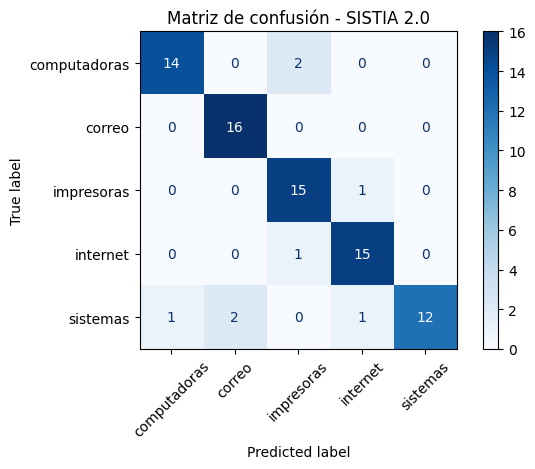

In [54]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.4 - EVALUACIÓN DEL MODELO SVM
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Realizar predicciones sobre los datos de evaluación
y_pred = modelo_svm.predict(X_test_tfidf)

# Calcular métricas generales
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

# Mostrar resultados
print("=" * 55)
print("EVALUACIÓN DEL CLASIFICADOR SVM - SISTIA 2.0")
print("=" * 55)

print("\nExpresiones evaluadas:", len(y_test))

print(f"\nAccuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nREPORTE DE CLASIFICACIÓN")
print("=" * 55)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# Generar matriz de confusión
matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=modelo_svm.classes_
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo_svm.classes_
)

visualizacion.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Matriz de confusión - SISTIA 2.0")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 13.2. Análisis de errores del clasificador

Se identificarán las expresiones que el modelo SVM clasificó incorrectamente durante la evaluación.

El objetivo es analizar posibles confusiones entre las cinco categorías de SISTIA y determinar qué características de los mensajes pueden dificultar el reconocimiento de intenciones.

Este análisis permitirá identificar oportunidades de mejora antes de integrar el clasificador con los flujos de diagnóstico del asistente.

In [55]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.5 - ANÁLISIS DE ERRORES
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

import pandas as pd

# Crear tabla con los resultados de evaluación
resultados_svm = pd.DataFrame({
    "mensaje": X_test.values,
    "categoria_real": y_test.values,
    "categoria_predicha": y_pred
})

# Identificar si la clasificación fue correcta
resultados_svm["correcto"] = (
    resultados_svm["categoria_real"]
    == resultados_svm["categoria_predicha"]
)

# Seleccionar únicamente las clasificaciones incorrectas
errores_svm = resultados_svm[
    resultados_svm["correcto"] == False
].copy()

# Mostrar resultados
print("=" * 55)
print("ANÁLISIS DE ERRORES - SISTIA 2.0")
print("=" * 55)

print("\nTotal de expresiones evaluadas:", len(resultados_svm))
print("Clasificaciones correctas:", resultados_svm["correcto"].sum())
print("Clasificaciones incorrectas:", len(errores_svm))

print("\nEXPRESIONES CLASIFICADAS INCORRECTAMENTE")
print("=" * 55)

print(
    errores_svm[
        ["mensaje", "categoria_real", "categoria_predicha"]
    ].to_string(index=False)
)

ANÁLISIS DE ERRORES - SISTIA 2.0

Total de expresiones evaluadas: 80
Clasificaciones correctas: 72
Clasificaciones incorrectas: 8

EXPRESIONES CLASIFICADAS INCORRECTAMENTE
                                                 mensaje categoria_real categoria_predicha
           No puedo abrir Navision aunque tengo internet       sistemas           internet
                                No puedo abrir el saltoo       sistemas             correo
                                  El zennnio no responde       sistemas       computadoras
                           La máquina no quiere encender   computadoras         impresoras
Navision me solicita actualizar mi contraseña de Windows       sistemas             correo
     La impresora de administración aparece sin conexión     impresoras           internet
                                      No me deja navegar       internet         impresoras
                              No sale nada en el monitor   computadoras         impresoras


### 13.3. Pruebas con expresiones nuevas y lenguaje informal

Se realizarán pruebas adicionales con mensajes redactados de manera informal, errores ortográficos y expresiones que pueden generar confusión entre categorías.

El objetivo es analizar la capacidad de generalización del clasificador SVM ante diferentes formas de describir incidencias técnicas.

Estas pruebas complementan la evaluación inicial realizada con las 80 expresiones reservadas.

Los resultados permitirán identificar limitaciones del modelo y proponer mejoras para la versión final de SISTIA.

In [56]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.6 - PRUEBAS CON EXPRESIONES NUEVAS
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

import pandas as pd

# Expresiones para evaluar la generalización del modelo
pruebas_nuevas = [
    ("Kiero imprimir y no me deja", "impresoras"),
    ("Mi inpresora no funciona", "impresoras"),
    ("Se atoraron las hojas cuando imprimia", "impresoras"),
    ("No tengo internt en mi compu", "internet"),
    ("La red se cae a cada rato", "internet"),
    ("No puedo navegar por ninguna pagina", "internet"),
    ("Mi makina no prende", "computadoras"),
    ("La pantalla esta negra pero la pc prende", "computadoras"),
    ("El monitor no muestra nada", "computadoras"),
    ("No puedo entrar al navicion", "sistemas"),
    ("El sistema de las llaves no abre", "sistemas"),
    ("No puedo consultar las habitaciones en zennio", "sistemas"),
    ("No me llegan los mails", "correo"),
    ("No puedo mandar mensajes por outlook", "correo"),
    ("Mi correo no sincroniza", "correo")
]

# Separar mensajes y categorías correctas
mensajes_nuevos = [fila[0] for fila in pruebas_nuevas]
categorias_reales = [fila[1] for fila in pruebas_nuevas]

# Aplicar el vectorizador ya entrenado
X_nuevos_tfidf = vectorizador.transform(mensajes_nuevos)

# Realizar predicciones
predicciones_nuevas = modelo_svm.predict(X_nuevos_tfidf)

# Crear tabla de resultados
df_pruebas_nuevas = pd.DataFrame({
    "mensaje": mensajes_nuevos,
    "categoria_real": categorias_reales,
    "prediccion": predicciones_nuevas
})

# Comparar resultados
df_pruebas_nuevas["correcto"] = (
    df_pruebas_nuevas["categoria_real"]
    == df_pruebas_nuevas["prediccion"]
)

# Calcular exactitud
total_pruebas = len(df_pruebas_nuevas)
aciertos = df_pruebas_nuevas["correcto"].sum()
exactitud = aciertos / total_pruebas

print("=" * 60)
print("PRUEBAS CON EXPRESIONES NUEVAS - SISTIA 2.0")
print("=" * 60)

print("\nRESULTADOS:")
print(
    df_pruebas_nuevas.to_string(index=False)
)

print("\n" + "=" * 60)
print("RESUMEN DE EVALUACIÓN")
print("=" * 60)

print("\nTotal de pruebas:", total_pruebas)
print("Clasificaciones correctas:", aciertos)
print("Clasificaciones incorrectas:", total_pruebas - aciertos)
print(f"Exactitud: {exactitud * 100:.2f}%")

PRUEBAS CON EXPRESIONES NUEVAS - SISTIA 2.0

RESULTADOS:
                                      mensaje categoria_real   prediccion  correcto
                  Kiero imprimir y no me deja     impresoras   impresoras      True
                     Mi inpresora no funciona     impresoras   impresoras      True
        Se atoraron las hojas cuando imprimia     impresoras   impresoras      True
                 No tengo internt en mi compu       internet     internet      True
                    La red se cae a cada rato       internet     internet      True
          No puedo navegar por ninguna pagina       internet     internet      True
                          Mi makina no prende   computadoras computadoras      True
     La pantalla esta negra pero la pc prende   computadoras computadoras      True
                   El monitor no muestra nada   computadoras computadoras      True
                  No puedo entrar al navicion       sistemas     sistemas      True
             El sis

### 13.4. Verificación de independencia de las pruebas adicionales

Se comprobará si las 15 expresiones utilizadas en las pruebas complementarias coinciden con mensajes del conjunto de datos original.

Esta verificación permitirá identificar posibles coincidencias exactas o diferencias únicamente de formato.

Los resultados contribuirán a interpretar adecuadamente el desempeño del clasificador ante mensajes adicionales.

In [57]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.7 - VERIFICACIÓN DE EXPRESIONES NUEVAS
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

# Normalizar las 400 expresiones originales
expresiones_originales = set(
    df_sistia["texto"].apply(normalizar_texto)
)

# Verificar coincidencias con las 15 pruebas
df_pruebas_nuevas["mensaje_normalizado"] = (
    df_pruebas_nuevas["mensaje"].apply(normalizar_texto)
)

df_pruebas_nuevas["existe_en_dataset"] = (
    df_pruebas_nuevas["mensaje_normalizado"].isin(
        expresiones_originales
    )
)

print("=" * 60)
print("VERIFICACIÓN DE EXPRESIONES NUEVAS - SISTIA 2.0")
print("=" * 60)

print("\nResultados:")
print(
    df_pruebas_nuevas[
        ["mensaje", "existe_en_dataset"]
    ].to_string(index=False)
)

coincidencias = df_pruebas_nuevas["existe_en_dataset"].sum()

print("\n" + "=" * 60)
print("RESUMEN")
print("=" * 60)

print("\nExpresiones evaluadas:", len(df_pruebas_nuevas))
print("Coincidencias con el dataset:", coincidencias)
print(
    "Expresiones sin coincidencia exacta:",
    len(df_pruebas_nuevas) - coincidencias
)

VERIFICACIÓN DE EXPRESIONES NUEVAS - SISTIA 2.0

Resultados:
                                      mensaje  existe_en_dataset
                  Kiero imprimir y no me deja               True
                     Mi inpresora no funciona               True
        Se atoraron las hojas cuando imprimia              False
                 No tengo internt en mi compu              False
                    La red se cae a cada rato              False
          No puedo navegar por ninguna pagina              False
                          Mi makina no prende              False
     La pantalla esta negra pero la pc prende              False
                   El monitor no muestra nada              False
                  No puedo entrar al navicion              False
             El sistema de las llaves no abre              False
No puedo consultar las habitaciones en zennio              False
                       No me llegan los mails              False
         No puedo mandar mens

### 13.5. Evaluación complementaria sin coincidencias exactas

Durante la verificación de las 15 expresiones adicionales se identificaron dos mensajes que ya estaban presentes en el conjunto de datos original.

Por este motivo, se realizará un análisis complementario utilizando únicamente las 13 expresiones sin coincidencias exactas después de la normalización.

Esta evaluación permitirá documentar el comportamiento del clasificador ante mensajes adicionales, aunque no garantiza que sean completamente diferentes en significado de los utilizados durante el entrenamiento.

El resultado principal del modelo continuará siendo la evaluación realizada con las 80 expresiones reservadas.

In [58]:
# ==================================================
# SECCIÓN 13: CLASIFICADOR DE INTENCIONES
# PASO 5.8 - EVALUACIÓN COMPLEMENTARIA
# SISTIA - AVANCE DE PROYECTO 2
# ==================================================

# Seleccionar expresiones sin coincidencia exacta
pruebas_independientes = df_pruebas_nuevas[
    df_pruebas_nuevas["existe_en_dataset"] == False
].copy()

# Calcular resultados
total = len(pruebas_independientes)
aciertos = pruebas_independientes["correcto"].sum()
errores = total - aciertos

exactitud_independiente = aciertos / total if total > 0 else 0

print("=" * 60)
print("EVALUACIÓN COMPLEMENTARIA - SISTIA 2.0")
print("=" * 60)

print("\nExpresiones sin coincidencia exacta:", total)
print("Clasificaciones correctas:", aciertos)
print("Clasificaciones incorrectas:", errores)
print(f"Exactitud: {exactitud_independiente * 100:.2f}%")

print("\nDETALLE DE RESULTADOS")
print("=" * 60)

print(
    pruebas_independientes[
        ["mensaje", "categoria_real", "prediccion", "correcto"]
    ].to_string(index=False)
)

EVALUACIÓN COMPLEMENTARIA - SISTIA 2.0

Expresiones sin coincidencia exacta: 13
Clasificaciones correctas: 13
Clasificaciones incorrectas: 0
Exactitud: 100.00%

DETALLE DE RESULTADOS
                                      mensaje categoria_real   prediccion  correcto
        Se atoraron las hojas cuando imprimia     impresoras   impresoras      True
                 No tengo internt en mi compu       internet     internet      True
                    La red se cae a cada rato       internet     internet      True
          No puedo navegar por ninguna pagina       internet     internet      True
                          Mi makina no prende   computadoras computadoras      True
     La pantalla esta negra pero la pc prende   computadoras computadoras      True
                   El monitor no muestra nada   computadoras computadoras      True
                  No puedo entrar al navicion       sistemas     sistemas      True
             El sistema de las llaves no abre       sistemas 

# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
## PASO 6.1 - PREPARACIÓN DEL DATASET VISUAL
### SISTIA 2.0 - AVANCE DE PROYECTO 2

En esta sección implementaremos un modelo de clasificación
de imágenes utilizando EfficientNetB0.

El modelo trabajará con cinco categorías:

1. impresora
2. atasco_papel
3. computadora_dell
4. monitor_sin_senal
5. pantalla_error

In [59]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.1 - CONEXIÓN CON GOOGLE DRIVE
# SISTIA 2.0
# ============================================

from google.colab import drive

drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import os

ruta = "/content/drive/MyDrive"

if os.path.isdir(ruta):
    print("Google Drive está disponible")
    print("Carpetas encontradas:")
    print(os.listdir(ruta)[:20])
else:
    print("Google Drive todavía no está montado")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.2 - LOCALIZAR DATASET
# SISTIA 2.0
# ============================================

import os

ruta_dataset = "/content/drive/MyDrive/SISTIA_Proyecto_2/dataset_imagenes"

if os.path.exists(ruta_dataset):
    print("Dataset encontrado correctamente")
    print("\nCategorías disponibles:")

    for carpeta in sorted(os.listdir(ruta_dataset)):
        ruta_carpeta = os.path.join(ruta_dataset, carpeta)

        if os.path.isdir(ruta_carpeta):
            imagenes = [
                archivo for archivo in os.listdir(ruta_carpeta)
                if archivo.lower().endswith((".jpg", ".jpeg", ".png"))
            ]

            print(f"{carpeta}: {len(imagenes)} imágenes")
else:
    print("No se encontró la carpeta dataset_imagenes")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.3 - PREPARACIÓN DEL DATASET
# SISTIA 2.0
# ============================================

import tensorflow as tf

# Configuración de imágenes
IMG_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42

# Cargar imágenes para entrenamiento
dataset_entrenamiento = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Cargar imágenes para validación
dataset_validacion = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Obtener nombres de categorías
categorias = dataset_entrenamiento.class_names

print("\nCategorías reconocidas por SISTIA:")
for numero, categoria in enumerate(categorias):
    print(f"{numero}: {categoria}")

print("\nDataset preparado correctamente.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.4 - VISUALIZACIÓN DEL DATASET
# SISTIA 2.0
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

for imagenes, etiquetas in dataset_entrenamiento.take(1):

    for i in range(min(8, len(imagenes))):

        plt.subplot(2, 4, i + 1)

        plt.imshow(imagenes[i].numpy().astype("uint8"))

        plt.title(categorias[etiquetas[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.5 - DISTRIBUCIÓN DEL DATASET
# SISTIA 2.0
# ============================================

import numpy as np
import pandas as pd

# Contar imágenes por categoría
def contar_imagenes(dataset):

    conteo = np.zeros(len(categorias), dtype=int)

    for imagenes, etiquetas in dataset:
        for etiqueta in etiquetas.numpy():
            conteo[etiqueta] += 1

    return conteo


# Contar imágenes de entrenamiento
conteo_entrenamiento = contar_imagenes(dataset_entrenamiento)

# Contar imágenes de validación
conteo_validacion = contar_imagenes(dataset_validacion)

# Crear tabla de resultados
distribucion = pd.DataFrame({
    "Categoria": categorias,
    "Entrenamiento": conteo_entrenamiento,
    "Validacion": conteo_validacion
})

distribucion["Total"] = (
    distribucion["Entrenamiento"] +
    distribucion["Validacion"]
)

print("DISTRIBUCIÓN DEL DATASET - SISTIA 2.0")
print("=" * 50)

print(distribucion.to_string(index=False))

print("\nTotal entrenamiento:", conteo_entrenamiento.sum())
print("Total validación:", conteo_validacion.sum())

# Detectar categorías sin imágenes en validación
sin_validacion = distribucion[
    distribucion["Validacion"] == 0
]

if not sin_validacion.empty:
    print("\nATENCIÓN: Hay categorías sin imágenes de validación.")
    print(sin_validacion["Categoria"].tolist())
else:
    print("\nTodas las categorías tienen imágenes de validación.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.6 - DIVISIÓN POR CATEGORÍA
# SISTIA 2.0
# ============================================

import os
import random
import tensorflow as tf
import pandas as pd

random.seed(42)

# Guardar rutas de imágenes por categoría
rutas_entrenamiento = []
rutas_validacion = []

etiquetas_entrenamiento = []
etiquetas_validacion = []

# Recorrer las cinco categorías
for indice, categoria in enumerate(categorias):

    carpeta = os.path.join(ruta_dataset, categoria)

    archivos = [
        os.path.join(carpeta, archivo)
        for archivo in sorted(os.listdir(carpeta))
        if archivo.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    # Mezclar fotografías
    random.shuffle(archivos)

    # Reservar aproximadamente 20% para validación
    cantidad_validacion = max(1, round(len(archivos) * 0.2))

    archivos_validacion = archivos[:cantidad_validacion]
    archivos_entrenamiento = archivos[cantidad_validacion:]

    rutas_entrenamiento.extend(archivos_entrenamiento)
    rutas_validacion.extend(archivos_validacion)

    etiquetas_entrenamiento.extend(
        [indice] * len(archivos_entrenamiento)
    )

    etiquetas_validacion.extend(
        [indice] * len(archivos_validacion)
    )

# Mostrar distribución
distribucion_equilibrada = pd.DataFrame({
    "Categoria": categorias,
    "Entrenamiento": [
        etiquetas_entrenamiento.count(i)
        for i in range(len(categorias))
    ],
    "Validacion": [
        etiquetas_validacion.count(i)
        for i in range(len(categorias))
    ]
})

distribucion_equilibrada["Total"] = (
    distribucion_equilibrada["Entrenamiento"]
    + distribucion_equilibrada["Validacion"]
)

print("NUEVA DISTRIBUCIÓN - SISTIA 2.0")
print("=" * 50)

print(distribucion_equilibrada.to_string(index=False))

print("\nTotal entrenamiento:", len(rutas_entrenamiento))
print("Total validación:", len(rutas_validacion))

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.7 - CREAR DATASETS DEFINITIVOS
# SISTIA 2.0
# ============================================

import tensorflow as tf

# Función para cargar y preparar cada imagen
def preparar_imagen(ruta, etiqueta):

    imagen = tf.io.read_file(ruta)

    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False
    )

    imagen.set_shape([None, None, 3])

    imagen = tf.image.resize(imagen, IMG_SIZE)

    imagen = tf.cast(imagen, tf.float32)

    return imagen, etiqueta


# Crear dataset de entrenamiento
dataset_entrenamiento_final = tf.data.Dataset.from_tensor_slices(
    (rutas_entrenamiento, etiquetas_entrenamiento)
)

dataset_entrenamiento_final = (
    dataset_entrenamiento_final
    .map(preparar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(rutas_entrenamiento), seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Crear dataset de validación
dataset_validacion_final = tf.data.Dataset.from_tensor_slices(
    (rutas_validacion, etiquetas_validacion)
)

dataset_validacion_final = (
    dataset_validacion_final
    .map(preparar_imagen, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)


# Verificar resultados
print("DATASETS DEFINITIVOS - SISTIA 2.0")
print("=" * 50)

print("Imágenes de entrenamiento:", len(rutas_entrenamiento))
print("Imágenes de validación:", len(rutas_validacion))

print("\nTamaño de imagen:", IMG_SIZE)
print("Tamaño de lote:", BATCH_SIZE)

print("\nDatasets preparados correctamente.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.8 - DETECCIÓN DE IMÁGENES DUPLICADAS
# SISTIA 2.0
# ============================================

import hashlib
import os
from collections import defaultdict

# Obtener huella digital de cada imagen
def calcular_hash(ruta):

    with open(ruta, "rb") as archivo:
        return hashlib.sha256(archivo.read()).hexdigest()


# Agrupar imágenes con contenido idéntico
imagenes_por_hash = defaultdict(list)

todas_las_rutas = (
    rutas_entrenamiento + rutas_validacion
)

for ruta in todas_las_rutas:
    hash_imagen = calcular_hash(ruta)
    imagenes_por_hash[hash_imagen].append(ruta)


# Identificar duplicados
duplicados = {
    clave: rutas
    for clave, rutas in imagenes_por_hash.items()
    if len(rutas) > 1
}

print("VERIFICACIÓN DE DUPLICADOS - SISTIA 2.0")
print("=" * 50)

print("Total de imágenes:", len(todas_las_rutas))
print("Grupos de duplicados exactos:", len(duplicados))

if duplicados:

    for numero, rutas in enumerate(duplicados.values(), 1):

        print(f"\nGrupo duplicado {numero}:")

        for ruta in rutas:
            print("-", os.path.basename(ruta))

else:
    print("\nNo se encontraron imágenes exactamente duplicadas.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.9 - DETECTAR IMÁGENES SIMILARES
# SISTIA 2.0
# ============================================

from PIL import Image
import numpy as np
import os

# Calcular una representación perceptual de la imagen
def calcular_hash_perceptual(ruta):

    with Image.open(ruta) as imagen:
        imagen = imagen.convert("L")
        imagen = imagen.resize((32, 32))

        pixeles = np.array(imagen, dtype=np.float32)

    # Transformada discreta del coseno
    import cv2

    dct = cv2.dct(pixeles)

    frecuencias = dct[:8, :8]

    mediana = np.median(frecuencias[1:, :])

    return frecuencias > mediana


# Calcular hashes de todas las fotografías
hashes = {}

for ruta in todas_las_rutas:
    hashes[ruta] = calcular_hash_perceptual(ruta)


# Buscar imágenes similares
similares = []

rutas = list(hashes.keys())

for i in range(len(rutas)):

    for j in range(i + 1, len(rutas)):

        distancia = np.sum(
            hashes[rutas[i]] != hashes[rutas[j]]
        )

        if distancia <= 8:

            similares.append((
                rutas[i],
                rutas[j],
                int(distancia)
            ))


print("ANÁLISIS DE SIMILITUD - SISTIA 2.0")
print("=" * 50)

print("Imágenes analizadas:", len(rutas))
print("Pares potencialmente similares:", len(similares))

for ruta1, ruta2, distancia in similares:

    print("\nImagen 1:", os.path.basename(ruta1))
    print("Imagen 2:", os.path.basename(ruta2))
    print("Distancia perceptual:", distancia)

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.10 - VISUALIZAR IMÁGENES SIMILARES
# SISTIA 2.0
# ============================================

import matplotlib.pyplot as plt
from PIL import Image
import os

print("REVISIÓN VISUAL DE IMÁGENES SIMILARES")
print("=" * 50)

for numero, (ruta1, ruta2, distancia) in enumerate(similares, 1):

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    with Image.open(ruta1) as imagen1:
        axes[0].imshow(imagen1.convert("RGB"))

    axes[0].set_title(os.path.basename(ruta1))
    axes[0].axis("off")

    with Image.open(ruta2) as imagen2:
        axes[1].imshow(imagen2.convert("RGB"))

    axes[1].set_title(os.path.basename(ruta2))
    axes[1].axis("off")

    plt.suptitle(
        f"Par {numero} - Distancia perceptual: {distancia}"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.11 - AGRUPAR IMÁGENES RELACIONADAS
# SISTIA 2.0
# ============================================

import os
import pandas as pd

# Obtener todas las imágenes del dataset
registros = []

for categoria in sorted(os.listdir(ruta_dataset)):

    ruta_categoria = os.path.join(ruta_dataset, categoria)

    if not os.path.isdir(ruta_categoria):
        continue

    for archivo in sorted(os.listdir(ruta_categoria)):

        if archivo.lower().endswith((".jpg", ".jpeg", ".png")):

            # Identificar el equipo a partir del nombre
            nombre = os.path.splitext(archivo)[0]

            partes = nombre.split("_")

            if len(partes) > 1 and partes[-1].isdigit():
                grupo = "_".join(partes[:-1])
            else:
                grupo = nombre

            registros.append({
                "Categoria": categoria,
                "Imagen": archivo,
                "Grupo": grupo,
                "Ruta": os.path.join(ruta_categoria, archivo)
            })

# Crear tabla
df_imagenes = pd.DataFrame(registros)

print("=" * 60)
print("AGRUPACIÓN DE IMÁGENES - SISTIA 2.0")
print("=" * 60)

print("\nTotal de imágenes:", len(df_imagenes))

print("\nGrupos identificados:")

resumen_grupos = (
    df_imagenes
    .groupby(["Categoria", "Grupo"])
    .size()
    .reset_index(name="Cantidad")
)

print(resumen_grupos.to_string(index=False))

print("\nTotal de grupos:", len(resumen_grupos))

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.12 - REVISIÓN DE GRUPOS
# SISTIA 2.0
# ============================================

print("=" * 60)
print("REVISIÓN DE GRUPOS - SISTIA 2.0")
print("=" * 60)

for (categoria, grupo), datos in df_imagenes.groupby(
    ["Categoria", "Grupo"], sort=True
):

    print(f"\nCATEGORÍA: {categoria}")
    print(f"GRUPO: {grupo}")
    print(f"TOTAL: {len(datos)} imágenes")

    print("-" * 50)

    for archivo in datos["Imagen"]:
        print("  -", archivo)

print("\n" + "=" * 60)
print("REVISIÓN FINALIZADA")
print("=" * 60)

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.13 - CREACIÓN DEL MODELO EfficientNetB0
# SISTIA 2.0
# ============================================

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

# Configuración
IMG_SIZE = (224, 224)
NUM_CLASES = len(categorias)

# Cargar EfficientNetB0 preentrenado
modelo_base = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

# Congelar las capas del modelo base
modelo_base.trainable = False

# Construir modelo de SISTIA
modelo_sistia = models.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # Aumento de datos durante el entrenamiento
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),

    # Modelo preentrenado
    modelo_base,

    # Clasificación
    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(
        NUM_CLASES,
        activation="softmax"
    )

])

# Compilar modelo
modelo_sistia.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("=" * 60)
print("MODELO DE RECONOCIMIENTO - SISTIA 2.0")
print("=" * 60)

print("\nCategorías:", NUM_CLASES)

print("\nArquitectura del modelo:")

modelo_sistia.summary()

print("\nModelo creado correctamente.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.14 - PREPARAR ENTRENAMIENTO
# SISTIA 2.0
# ============================================

import tensorflow as tf

print("=" * 60)
print("PREPARACIÓN DEL ENTRENAMIENTO - SISTIA 2.0")
print("=" * 60)

# Verificar categorías
print("\nCategorías reconocidas:")

for numero, categoria in enumerate(categorias):
    print(f"{numero}: {categoria}")

# Verificar cantidad de imágenes
cantidad_entrenamiento = sum(
    1 for _ in dataset_entrenamiento.unbatch()
)

cantidad_validacion = sum(
    1 for _ in dataset_validacion.unbatch()
)

print("\nImágenes de entrenamiento:", cantidad_entrenamiento)
print("Imágenes de validación:", cantidad_validacion)

# Optimizar lectura de imágenes
AUTOTUNE = tf.data.AUTOTUNE

dataset_entrenamiento = dataset_entrenamiento.prefetch(
    buffer_size=AUTOTUNE
)

dataset_validacion = dataset_validacion.prefetch(
    buffer_size=AUTOTUNE
)

print("\nDatasets preparados correctamente.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.15 - ENTRENAMIENTO EfficientNetB0
# SISTIA 2.0
# ============================================

import tensorflow as tf

print("=" * 60)
print("ENTRENAMIENTO DEL MODELO - SISTIA 2.0")
print("=" * 60)

# Configuración
EPOCAS = 15

# Detener entrenamiento si no mejora
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Entrenar modelo
historial = modelo_sistia.fit(
    dataset_entrenamiento,
    validation_data=dataset_validacion,
    epochs=EPOCAS,
    callbacks=[early_stopping],
    verbose=1
)

print("\n" + "=" * 60)
print("ENTRENAMIENTO FINALIZADO - SISTIA 2.0")
print("=" * 60)

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.16 - EVALUACIÓN DEL MODELO
# SISTIA 2.0
# ============================================

import tensorflow as tf

print("=" * 60)
print("EVALUACIÓN DEL MODELO - SISTIA 2.0")
print("=" * 60)

# Evaluar modelo con imágenes de validación
resultado = modelo_sistia.evaluate(
    dataset_validacion,
    verbose=1
)

# Obtener métricas
perdida = resultado[0]
precision = resultado[1]

print("\n" + "=" * 60)
print("RESULTADOS DE EVALUACIÓN")
print("=" * 60)

print(f"\nPrecisión de validación: {precision * 100:.2f}%")
print(f"Pérdida de validación: {perdida:.4f}")

print("\nImágenes utilizadas para validación: 10")

print("\nEvaluación finalizada correctamente.")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.17 - MATRIZ DE CONFUSIÓN
# SISTIA 2.0
# ============================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

# Obtener etiquetas reales
etiquetas_reales = []

for imagenes, etiquetas in dataset_validacion:
    etiquetas_reales.extend(etiquetas.numpy())

etiquetas_reales = np.array(etiquetas_reales)

# Realizar predicciones
predicciones = modelo_sistia.predict(dataset_validacion)

# Obtener categoría con mayor probabilidad
etiquetas_predichas = np.argmax(predicciones, axis=1)

# Crear matriz de confusión
matriz = confusion_matrix(
    etiquetas_reales,
    etiquetas_predichas,
    labels=range(len(categorias))
)

# Mostrar matriz
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=categorias
)

plt.figure(figsize=(10, 7))

visualizacion.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Matriz de confusión - SISTIA 2.0")
plt.tight_layout()
plt.show()

# Reporte de clasificación
print("\n" + "=" * 60)
print("REPORTE DE CLASIFICACIÓN - SISTIA 2.0")
print("=" * 60)

print(
    classification_report(
        etiquetas_reales,
        etiquetas_predichas,
        labels=range(len(categorias)),
        target_names=categorias,
        zero_division=0
    )
)

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.18 - EVALUACIÓN CORREGIDA
# SISTIA 2.0
# ============================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score
)

# Listas para almacenar resultados
etiquetas_reales = []
etiquetas_predichas = []

# Evaluar imágenes y etiquetas en el mismo recorrido
for imagenes, etiquetas in dataset_validacion:

    # Obtener predicciones del modelo
    predicciones = modelo_sistia.predict(
        imagenes,
        verbose=0
    )

    # Identificar categoría predicha
    predichas = np.argmax(predicciones, axis=1)

    # Guardar etiquetas reales
    etiquetas_reales.extend(etiquetas.numpy())

    # Guardar predicciones
    etiquetas_predichas.extend(predichas)

# Convertir a arreglos NumPy
etiquetas_reales = np.array(etiquetas_reales)
etiquetas_predichas = np.array(etiquetas_predichas)

# Calcular precisión
precision = accuracy_score(
    etiquetas_reales,
    etiquetas_predichas
)

print("=" * 60)
print("EVALUACIÓN CORREGIDA - SISTIA 2.0")
print("=" * 60)

print(f"\nImágenes evaluadas: {len(etiquetas_reales)}")
print(f"Precisión obtenida: {precision * 100:.2f}%")

# Crear matriz de confusión
matriz = confusion_matrix(
    etiquetas_reales,
    etiquetas_predichas,
    labels=range(len(categorias))
)

# Visualizar resultados
visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=categorias
)

visualizacion.plot(
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Matriz de confusión corregida - SISTIA 2.0")
plt.tight_layout()
plt.show()

# Reporte de clasificación
print("\n" + "=" * 60)
print("REPORTE DE CLASIFICACIÓN CORREGIDO")
print("=" * 60)

print(
    classification_report(
        etiquetas_reales,
        etiquetas_predichas,
        labels=range(len(categorias)),
        target_names=categorias,
        zero_division=0
    )
)

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.19 - GUARDAR MODELO ENTRENADO
# SISTIA 2.0
# ============================================

import os

# Carpeta del proyecto
ruta_proyecto = "/content/drive/MyDrive/SISTIA_Proyecto_2"

# Carpeta para guardar el modelo
ruta_modelos = os.path.join(ruta_proyecto, "modelos")

# Crear carpeta si no existe
os.makedirs(ruta_modelos, exist_ok=True)

# Ruta del modelo
ruta_modelo = os.path.join(
    ruta_modelos,
    "SISTIA_2_EfficientNetB0.keras"
)

# Guardar modelo entrenado
modelo_sistia.save(ruta_modelo)

print("=" * 60)
print("MODELO GUARDADO - SISTIA 2.0")
print("=" * 60)

print("\nModelo:", ruta_modelo)
print("Estado: Guardado correctamente")

In [ ]:
# ============================================
# SECCIÓN 14: RECONOCIMIENTO DE IMÁGENES
# PASO 6.20 - PRUEBA DE RECONOCIMIENTO
# SISTIA 2.0
# ============================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Seleccionar una imagen del dataset
ruta_imagen = os.path.join(
    ruta_dataset,
    "monitor_sin_senal",
    "Monitor_dell_01.jpeg"
)

# Cargar imagen
imagen = tf.keras.utils.load_img(
    ruta_imagen,
    target_size=(224, 224)
)

# Convertir imagen a arreglo
imagen_array = tf.keras.utils.img_to_array(imagen)

# Agregar dimensión para el modelo
imagen_array = np.expand_dims(imagen_array, axis=0)

# Realizar predicción
prediccion = modelo_sistia.predict(
    imagen_array,
    verbose=0
)

# Obtener categoría y confianza
indice = np.argmax(prediccion[0])

categoria_detectada = categorias[indice]

confianza = prediccion[0][indice] * 100

# Mostrar resultados
print("=" * 60)
print("RECONOCIMIENTO DE IMÁGENES - SISTIA 2.0")
print("=" * 60)

print(f"\nCategoría detectada: {categoria_detectada}")
print(f"Confianza del modelo: {confianza:.2f}%")

# Mostrar imagen analizada
plt.figure(figsize=(7, 5))
plt.imshow(imagen)
plt.title(f"SISTIA: {categoria_detectada}")
plt.axis("off")
plt.show()

In [60]:
# ==================================================
# SECCIÓN 15: INTEGRACIÓN MULTIMODAL
# PASO 7.1 - VERIFICACIÓN DE COMPONENTES
# SISTIA 2.0 - AVANCE DE PROYECTO 2
# ==================================================

print("=" * 60)
print("VERIFICACIÓN DE COMPONENTES - SISTIA 2.0")
print("=" * 60)

# Verificar clasificador de texto
if "modelo_svm" in globals():
    print("\n[OK] Clasificador SVM disponible")
else:
    print("\n[ERROR] Clasificador SVM no disponible")

# Verificar vectorizador TF-IDF
if "vectorizador" in globals():
    print("[OK] Vectorizador TF-IDF disponible")
else:
    print("[ERROR] Vectorizador TF-IDF no disponible")

# Verificar modelo de imágenes
if "modelo_sistia" in globals():
    print("[OK] Modelo EfficientNetB0 disponible")
else:
    print("[ERROR] Modelo EfficientNetB0 no disponible")

# Verificar categorías visuales
if "categorias" in globals():
    print("[OK] Categorías de imágenes disponibles")
else:
    print("[ERROR] Categorías de imágenes no disponibles")

# Verificar función de preprocesamiento
if "preprocesar_texto" in globals():
    print("[OK] Preprocesamiento de texto disponible")
else:
    print("[ERROR] Preprocesamiento de texto no disponible")

print("\n" + "=" * 60)
print("VERIFICACIÓN FINALIZADA")
print("=" * 60)

VERIFICACIÓN DE COMPONENTES - SISTIA 2.0

[OK] Clasificador SVM disponible
[OK] Vectorizador TF-IDF disponible
[OK] Modelo EfficientNetB0 disponible
[OK] Categorías de imágenes disponibles
[OK] Preprocesamiento de texto disponible

VERIFICACIÓN FINALIZADA


In [68]:
# ==================================================
# SECCIÓN 15: INTEGRACIÓN MULTIMODAL
# PASO 7.2 - CLASIFICACIÓN DE TEXTO E IMÁGENES
# SISTIA 2.0
# ==================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

def sistia_multimodal(mensaje, ruta_imagen):

    print("=" * 60)
    print("SISTIA 2.0 - ANÁLISIS MULTIMODAL")
    print("=" * 60)

    # ----------------------------------------------
    # 1. ANALIZAR EL MENSAJE DEL COLABORADOR
    # ----------------------------------------------

    texto_procesado = preprocesar_texto(mensaje)

    texto_vectorizado = vectorizador.transform(
        [texto_procesado]
    )

    intencion = modelo_svm.predict(
        texto_vectorizado
    )[0]

    print("\nMensaje del colaborador:")
    print(mensaje)

    print("\nIntención detectada:")
    print(intencion)

    # ----------------------------------------------
    # 2. ANALIZAR LA IMAGEN
    # ----------------------------------------------

    imagen = tf.keras.utils.load_img(
        ruta_imagen,
        target_size=(224, 224)
    )

    imagen_array = tf.keras.utils.img_to_array(imagen)

    imagen_array = np.expand_dims(
        imagen_array, axis=0
    )

    predicciones = modelo_sistia.predict(
        imagen_array,
        verbose=0
    )

    # Obtener índice de la categoría detectada
    indice = int(np.argmax(predicciones[0]))

# Obtener nombres de categorías en el orden del entrenamiento
    nombres_categorias = [
    "atasco_papel",
    "computadora_dell",
    "impresora",
    "monitor_sin_senal",
    "pantalla_error"
    ]

# Convertir el índice al nombre correspondiente
    categoria_imagen = nombres_categorias[indice]

# Calcular porcentaje de confianza
    confianza = float(np.max(predicciones[0]) * 100)

    print("\nCategoría detectada en la imagen:")
    print(categoria_imagen)

    print(f"\nConfianza del modelo: {confianza:.2f}%")

    # ----------------------------------------------
    # 3. MOSTRAR LA IMAGEN
    # ----------------------------------------------

    plt.figure(figsize=(6, 5))

    plt.imshow(imagen)

    plt.title(
        f"SISTIA: {categoria_imagen}"
    )

    plt.axis("off")
    plt.show()

    # ----------------------------------------------
    # 4. RESULTADO INTEGRADO
    # ----------------------------------------------

    print("\n" + "=" * 60)
    print("RESULTADO MULTIMODAL")
    print("=" * 60)

    print("Intención del mensaje:", intencion)
    print("Clasificación de imagen:", categoria_imagen)

    print("\nSISTIA ha procesado correctamente")
    print("la información textual y visual.")

    return {
        "mensaje": mensaje,
        "intencion": intencion,
        "categoria_imagen": categoria_imagen,
        "confianza": confianza
    }


print("Función multimodal de SISTIA creada correctamente.")

Función multimodal de SISTIA creada correctamente.


Imagen encontrada correctamente.

SISTIA 2.0 - ANÁLISIS MULTIMODAL

Mensaje del colaborador:
Mi computadora prende, pero el monitor no muestra imagen

Intención detectada:
computadoras

Categoría detectada en la imagen:
monitor_sin_senal

Confianza del modelo: 56.80%


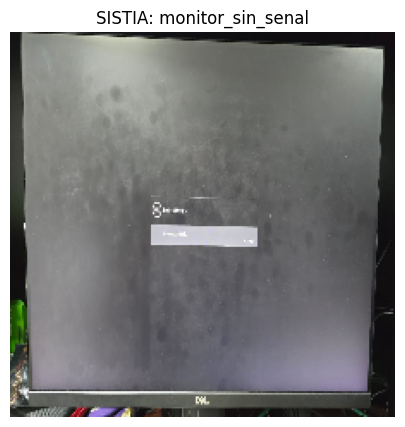


RESULTADO MULTIMODAL
Intención del mensaje: computadoras
Clasificación de imagen: monitor_sin_senal

SISTIA ha procesado correctamente
la información textual y visual.


In [69]:
# ==================================================
# SECCIÓN 15: INTEGRACIÓN MULTIMODAL
# PASO 7.3 - PRIMERA PRUEBA MULTIMODAL
# SISTIA 2.0
# ==================================================

import os

# Mensaje del colaborador
mensaje = "Mi computadora prende, pero el monitor no muestra imagen"

# Fotografía del problema
ruta_imagen = os.path.join(
    ruta_dataset,
    "monitor_sin_senal",
    "Monitor_dell_01.jpeg"
)

# Verificar que la imagen existe
if os.path.exists(ruta_imagen):

    print("Imagen encontrada correctamente.\n")

    resultado = sistia_multimodal(
        mensaje,
        ruta_imagen
    )

else:
    print("ERROR: No se encontró la imagen.")
    print("Ruta:", ruta_imagen)

In [70]:
# ==================================================
# SECCIÓN 15: INTEGRACIÓN MULTIMODAL
# PASO 7.4 - RESPUESTA INTELIGENTE
# SISTIA 2.0
# ==================================================

def respuesta_sistia(resultado):

    intencion = resultado["intencion"]
    categoria = resultado["categoria_imagen"]
    confianza = resultado["confianza"]

    print("\n" + "=" * 60)
    print("SISTIA 2.0 - ASISTENTE DE SOPORTE TÉCNICO")
    print("=" * 60)

    print("\nHe analizado tu mensaje y la fotografía.")

    print(f"\nProblema reportado: {intencion}")
    print(f"Imagen identificada: {categoria}")
    print(f"Confianza visual: {confianza:.2f}%")

    # Diagnóstico de monitor sin señal
    if intencion == "computadoras" and categoria == "monitor_sin_senal":

        print("\nSISTIA:")
        print("La fotografía parece mostrar un monitor sin señal de video.")

        if confianza < 70:
            print(
                "La identificación visual tiene una confianza "
                "limitada, por lo que debemos verificar el problema."
            )

        print("\nAntes de continuar, ¿qué has revisado?")

        print("1. Verifiqué que la computadora esté encendida.")
        print("2. Revisé que el monitor tenga energía.")
        print("3. Revisé el cable de video.")
        print("4. Ya revisé todo lo anterior.")
        print("5. Todavía no he revisado nada.")

        print("\nRecomendación inicial:")
        print(
            "Primero verifica el indicador de encendido "
            "de la computadora."
        )

        print(
            "Si está en blanco, podemos continuar "
            "revisando el monitor y sus conexiones."
        )

        print(
            "Si está en naranja, contacta al "
            "departamento de Sistemas."
        )

    # Diagnóstico de impresoras
    elif intencion == "impresoras" and categoria in [
        "impresora",
        "atasco_papel"
    ]:

        print("\nSISTIA:")

        if categoria == "atasco_papel":

            print(
                "La fotografía podría mostrar "
                "un atasco de papel."
            )

            print(
                "Verifica si existe papel atorado "
                "en las áreas accesibles de la impresora."
            )

            print(
                "No fuerces los componentes internos."
            )

        else:

            print(
                "La fotografía muestra una impresora."
            )

            print(
                "¿Qué problema presenta: no imprime, "
                "aparece desconectada o muestra un error?"
            )

    # Otros problemas
    else:

        print("\nSISTIA:")

        print(
            "He identificado información relacionada "
            "con una incidencia técnica."
        )

        print(
            "Necesito realizar algunas preguntas "
            "para determinar el procedimiento adecuado."
        )

    print("\n" + "=" * 60)
    print("ANÁLISIS MULTIMODAL FINALIZADO")
    print("=" * 60)


print("Sistema de respuestas de SISTIA creado correctamente.")

Sistema de respuestas de SISTIA creado correctamente.


In [71]:
# ==================================================
# SECCIÓN 15: INTEGRACIÓN MULTIMODAL
# PASO 7.5 - PRUEBA DE RESPUESTA INTELIGENTE
# SISTIA 2.0
# ==================================================

print("=" * 60)
print("PRUEBA DE RESPUESTA INTELIGENTE - SISTIA 2.0")
print("=" * 60)

# Utilizar los resultados del análisis multimodal
respuesta_sistia(resultado)

print("\nPrueba de integración completada.")

PRUEBA DE RESPUESTA INTELIGENTE - SISTIA 2.0

SISTIA 2.0 - ASISTENTE DE SOPORTE TÉCNICO

He analizado tu mensaje y la fotografía.

Problema reportado: computadoras
Imagen identificada: monitor_sin_senal
Confianza visual: 56.80%

SISTIA:
La fotografía parece mostrar un monitor sin señal de video.
La identificación visual tiene una confianza limitada, por lo que debemos verificar el problema.

Antes de continuar, ¿qué has revisado?
1. Verifiqué que la computadora esté encendida.
2. Revisé que el monitor tenga energía.
3. Revisé el cable de video.
4. Ya revisé todo lo anterior.
5. Todavía no he revisado nada.

Recomendación inicial:
Primero verifica el indicador de encendido de la computadora.
Si está en blanco, podemos continuar revisando el monitor y sus conexiones.
Si está en naranja, contacta al departamento de Sistemas.

ANÁLISIS MULTIMODAL FINALIZADO

Prueba de integración completada.
